本页集中展示基础抽样与四个案例的代码、运行结果和解读，可按目录直接阅读。各案例开头的链接通向正文的相应小节。

## 阅读与运行说明 {.unnumbered #sec-mc-nb-guide}

本地复现请在完整课程仓库中打开同名 Notebook，从第一个代码单元依次运行。所需环境包括 NumPy、pandas、Matplotlib、SciPy 和 statsmodels，配置方法见[软件配置](../../settings.qmd)。下方代码统一导入工具、设置图形样式并指定输出目录，各案例随后设置自己的参数与随机数发生器。

案例一、二、四使用教学模拟。案例三读取仓库 `data/monte-carlo/` 中的配套数据，无需重新下载行情。生成文件写入 `output/monte-carlo/cases/`，不修改输入数据。各案例的折叠部分提供补充分析，可按需展开。

In [1]:
#| code-fold: true
#| code-summary: "展开运行准备代码"
from pathlib import Path
from math import log, sqrt, exp, erf
import json
import os
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.sandbox.regression.gmm import IV2SLS
from IPython.display import display, Image, HTML

def show_table(frame, labels=None, percentages=(), digits=3):
    # 展示表使用易读名称与单位，原始数组和导出字段保持不变。
    table = frame.copy()
    for column in percentages:
        table[column] = table[column] * 100
    if labels:
        table = table.rename(columns=labels)
    display(HTML(table.to_html(index=False, border=0,
                              float_format=lambda value: f'{value:.{digits}f}')))

def find_course_root():
    # 根据课程数据与目录识别仓库，不依赖本机绝对路径。
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if ((candidate / 'data/monte-carlo/returns.csv').is_file()
                and (candidate / 'notebooks/monte-carlo').is_dir()):
            return candidate
    raise FileNotFoundError('请在完整课程仓库内启动；需要 data/monte-carlo/returns.csv。')

ROOT = find_course_root()
OUTPUT = Path(os.environ.get('FINECO_MC_OUTPUT', ROOT / 'output/monte-carlo/cases'))
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED = 20261001
plt.rcParams.update({'font.family': 'sans-serif',
                     'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans'],
                     'axes.unicode_minus': False, 'font.size': 11})
pd.set_option('display.max_columns', 16)
pd.set_option('display.width', 140)
show_table(pd.DataFrame({'项目': ['Python', 'NumPy', 'pandas', '基准种子'],
                         '设置': [platform.python_version(), np.__version__, pd.__version__, str(SEED)]}))

项目,设置
Python,3.12.16
NumPy,2.4.2
pandas,2.3.3
基准种子,20261001


In [2]:
#| include: false
case_results = {}

## 基础抽样与模拟设置 {.unnumbered #sec-mc-nb-basics}

[返回正文：几个基本概念](../../lectures/monte-carlo.qmd#sec-mc-basics)。

### 随机数、概率分布与抽样 {.unnumbered}

$U\sim U(0,1)$ 表示随机变量 $U$ 服从区间 $(0,1)$ 上的均匀分布，符号 $\sim$ 读作服从。均匀分布在区间内具有相同的概率密度，等长子区间获得相同的概率。下面分别抽取均匀、标准正态和均值为 1 的指数随机数，观察取值范围、对称性和右尾的区别。

每幅图均包含 10000 个抽样值，纵轴为概率密度。它们用于说明如何从给定概率分布抽样，尚不是一个完整的回归或金融决策案例。

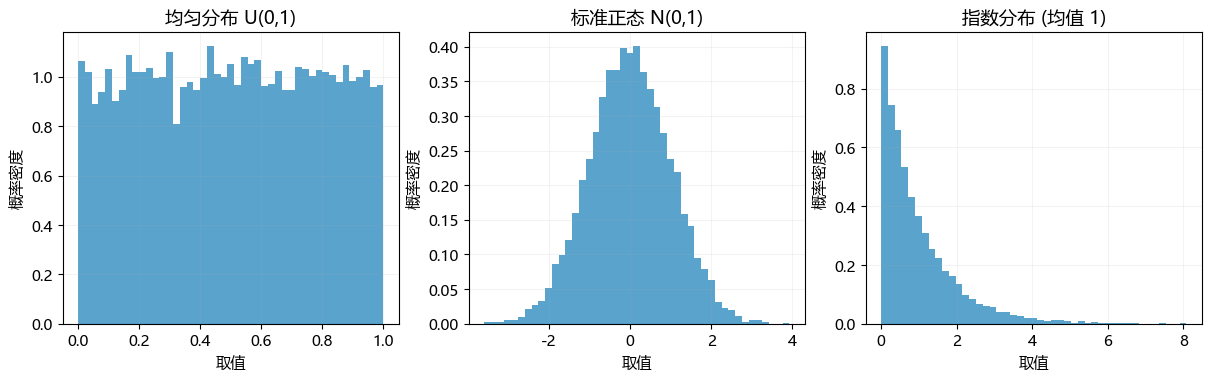

In [3]:
#| label: fig-mc-nb-three-distributions
#| fig-cap: "三种概率分布的抽样对照。各生成 10000 个值，保留各分布适合的横轴范围，不用图形宽度直接比较波动大小。"
distribution_rng = np.random.default_rng(SEED)
distribution_samples = {
    '均匀分布 U(0,1)': distribution_rng.uniform(size=10000),
    '标准正态 N(0,1)': distribution_rng.normal(size=10000),
    '指数分布 (均值 1)': distribution_rng.exponential(scale=1, size=10000),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout='constrained')
for axis, (name, sample) in zip(axes, distribution_samples.items()):
    axis.hist(sample, bins=45, density=True, alpha=.65, color='#0072B2')
    axis.set(title=name, xlabel='取值', ylabel='概率密度')
    axis.grid(alpha=.15)
plt.show()

In [4]:
distribution_summary = pd.DataFrame({name: {'样本均值': values.mean(), '样本标准差': values.std(ddof=1)}
                                     for name, values in distribution_samples.items()}).T
show_table(distribution_summary.rename_axis('分布').reset_index())

分布,样本均值,样本标准差
"均匀分布 U(0,1)",0.501,0.288
"标准正态 N(0,1)",-0.002,1.004
指数分布 (均值 1),0.994,0.995


### 从均匀随机数到目标分布 {.unnumbered}

对具有可用逆函数的连续累积分布函数 $F$，可以令 $X=F^{-1}(U)$。例如，均值为 1 的指数分布满足 $F(x)=1-e^{-x}$，因此 $X=-\log(1-U)$。下一段直接用均匀随机数作变换。

这只是逆分布函数抽样的一个例子。不同分布也可以使用其他抽样算法，不能把这个变换直接套到所有分布上。软件完成数值抽样，但需要模拟哪些变量、采用何种分布、参数如何确定，仍应根据分析问题设定。

In [5]:
inverse_rng = np.random.default_rng(SEED)
uniform_values = inverse_rng.random(10000)
exponential_values = -np.log1p(-uniform_values)
assert np.isfinite(exponential_values).all() and (exponential_values >= 0).all()
show_table(pd.DataFrame({'指标': ['均值', '标准差'],
                         '模拟结果': [exponential_values.mean(), exponential_values.std(ddof=1)],
                         '理论值': [1.0, 1.0]}))

指标,模拟结果,理论值
均值,1.002,1.000
标准差,1.003,1.000


### 随机种子、DGP 与重复次数 {.unnumbered}

相同的发生器、种子和调用顺序可以产生相同序列。下面分别初始化两个发生器，比较它们生成的前五个标准正态数。

数据生成过程 (data-generating process, DGP) 规定模拟变量如何产生，以及它们之间的关系和依赖设定。案例一将完整演示如何生成解释变量、扰动项和因变量，再通过重复估计观察估计量的表现。这里先区分：$n$ 是每次回归所用的样本量，$B$ 是重复生成样本并估计的次数。

In [6]:
rng1 = np.random.default_rng(12345)
rng2 = np.random.default_rng(12345)
a = rng1.normal(size=5)
b = rng2.normal(size=5)
show_table(pd.DataFrame({'第一次生成': a, '第二次生成': b, '两次之差': a - b}))

第一次生成,第二次生成,两次之差
-1.424,-1.424,0.000
1.264,1.264,0.000
-0.871,-0.871,0.000
-0.259,-0.259,0.000
-0.075,-0.075,0.000


::: {.callout-note collapse="true" title="补充核验：用模拟均值近似一个已知期望"}

设 $X\sim N(0,1)$，则 $E(X^{2})=1$。随着抽样数量增加，样本平方的平均值通常更接近该期望，单条随机序列不要求误差单调下降。

In [7]:
B_max = 100000
rng = np.random.default_rng(SEED)
x = rng.normal(size=B_max)
running_mean = np.cumsum(x**2) / np.arange(1, B_max + 1)
checkpoints = [10, 100, 1000, 10000, 100000]
running_summary = pd.DataFrame({
    "B": checkpoints,
    "MC_estimate": [running_mean[b-1] for b in checkpoints],
    "error": [running_mean[b-1] - 1 for b in checkpoints],
})
show_table(running_summary, {'B': '抽样数量 B', 'MC_estimate': '模拟均值', 'error': '与理论值之差'})

抽样数量 B,模拟均值,与理论值之差
10,1.074,0.074
100,1.061,0.061
1000,1.075,0.075
10000,0.992,-0.008
100000,1.000,0.000


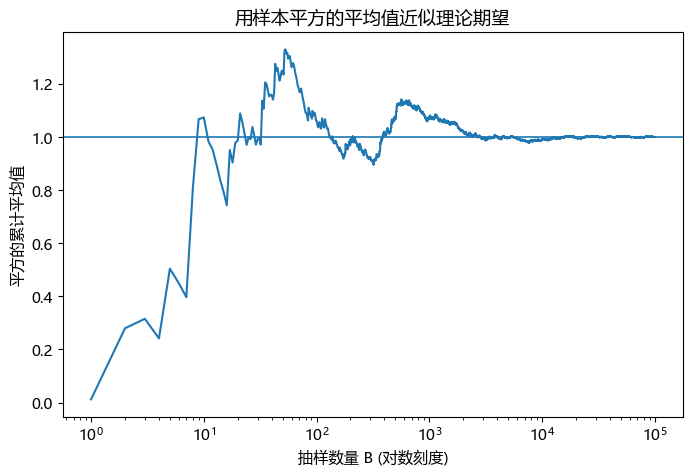

In [8]:
#| label: fig-mc-nb-running-mean
#| fig-cap: "标准正态平方的累计平均值与理论期望 1。"
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(1, B_max + 1), running_mean)
ax.axhline(1.0, linewidth=1.2)
ax.set_xscale("log")
ax.set_xlabel("抽样数量 B (对数刻度)")
ax.set_ylabel("平方的累计平均值")
ax.set_title("用样本平方的平均值近似理论期望")
plt.show()

:::

## 案例一：用模拟理解计量性质 {.unnumbered #sec-mc-nb-econometrics}

[返回正文：案例一](../../lectures/monte-carlo.qmd#sec-mc-econometrics)。

本例在已知参数真值的 DGP 中，考察普通最小二乘法 (OLS) 与工具变量法 (IV) 的估计表现。OLS 部分采用 $Y_{i}=1+2X_{i}+u_{i}$，其中 $X_{i}$ 为解释变量，$u_{i}$ 为扰动项，二者相互独立且均服从标准正态分布，不同观测之间也独立。每次重新生成整个样本，再估计和保存斜率。

### OLS 的无偏性 {.unnumbered}

固定 $n=100$，重复 $B=5000$ 次。输出均值与真值 2 的差作为 MC 偏差，不能把一次估计或有限次均值当作无偏性的证明。

In [9]:
def ols_mc(n=100, B=5000, beta0=1.0, beta1=2.0, seed=SEED):
    rng = np.random.default_rng(seed)
    bhat = np.empty(B)

    for b in range(B):
        x = rng.normal(0, 1, n)
        u = rng.normal(0, 1, n)
        y = beta0 + beta1 * x + u

        X = sm.add_constant(x)
        fit = sm.OLS(y, X).fit()
        bhat[b] = fit.params[1]

    return bhat

bhat_100 = ols_mc(n=100, B=5000)
unbiased_summary = pd.Series({
    "true_beta": 2.0,
    "mean_beta_hat": bhat_100.mean(),
    "bias": bhat_100.mean() - 2.0,
    "empirical_sd": bhat_100.std(ddof=1),
})
show_table(unbiased_summary.rename_axis('指标').rename('数值').reset_index().replace({'true_beta': '参数真值', 'mean_beta_hat': '估计均值', 'bias': 'MC 偏差', 'empirical_sd': '经验标准差'}), digits=6)

指标,数值
参数真值,2.000000
估计均值,2.001526
MC 偏差,0.001526
经验标准差,0.102839


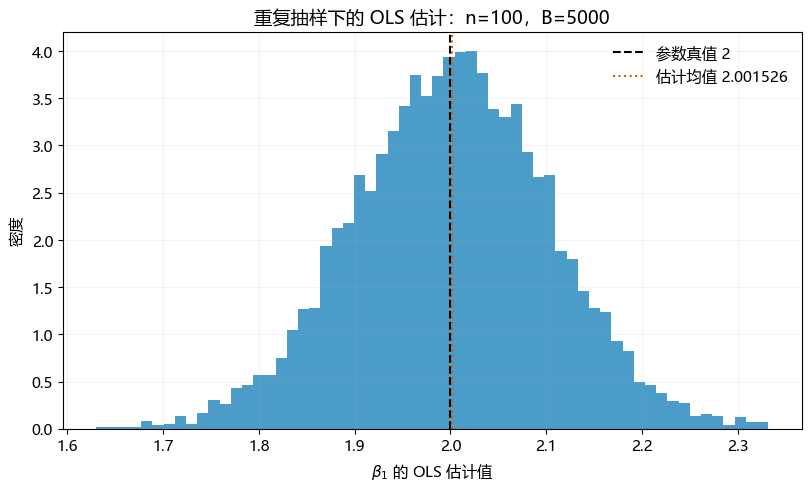

In [10]:
#| label: fig-mc-nb-ols-unbiased
#| fig-cap: "OLS 无偏性：估计分布、参数真值与 MC 均值。"
plt.rcParams.update({
    'font.family': 'Microsoft YaHei', 'font.size': 11,
    'axes.unicode_minus': False,
})
colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#666666']
line_styles = ['-', '--', '-.', ':', (0, (5, 1, 1, 1))]

# 无偏性：完整直方图与估计均值，不将单次估计等同于期望。
fig, axis = plt.subplots(figsize=(8, 4.8), layout='constrained')
axis.hist(bhat_100, bins=60, density=True, color=colors[0], alpha=.7)
axis.axvline(2, color='black', linestyle='--', label='参数真值 2')
axis.axvline(bhat_100.mean(), color=colors[1], linestyle=':',
             label=f'估计均值 {bhat_100.mean():.6f}')
axis.set(xlabel=r'$\beta_{1}$ 的 OLS 估计值', ylabel='密度',
         title='重复抽样下的 OLS 估计：n=100，B=5000')
axis.legend(frameon=False)
axis.grid(alpha=.15)
plt.show()

模拟得到的估计均值约为 2.001526，与真值 2 接近。图中估计值分布在真值线两侧，平均偏离约为 0.001526。有限次模拟与无偏性的理论结论相符，但不能代替数学证明。

### OLS 的一致性 {.unnumbered}

保持 DGP 不变，改变每次回归的样本量，各组重复 3000 次。左图比较估计分布，右图和表比较经验标准差。图形只使用统一显示窗口，没有将窗口外的估计值从统计量中删除。

In [11]:
sample_sizes = [20, 50, 100, 500, 2000]
ols_results = {}

for n in sample_sizes:
    vals = ols_mc(n=n, B=3000, seed=SEED + n)
    ols_results[n] = vals

ols_summary = pd.DataFrame([
    {
        "n": n,
        "mean_beta_hat": vals.mean(),
        "bias": vals.mean() - 2.0,
        "empirical_sd": vals.std(ddof=1),
    }
    for n, vals in ols_results.items()
])

show_table(ols_summary, {'n': '样本量 n', 'mean_beta_hat': '估计均值', 'bias': 'MC 偏差', 'empirical_sd': '经验标准差'})

样本量 n,估计均值,MC 偏差,经验标准差
20,2.004,0.004,0.244
50,2.002,0.002,0.143
100,1.997,-0.003,0.101
500,2.000,0.000,0.045
2000,2.000,-0.000,0.023


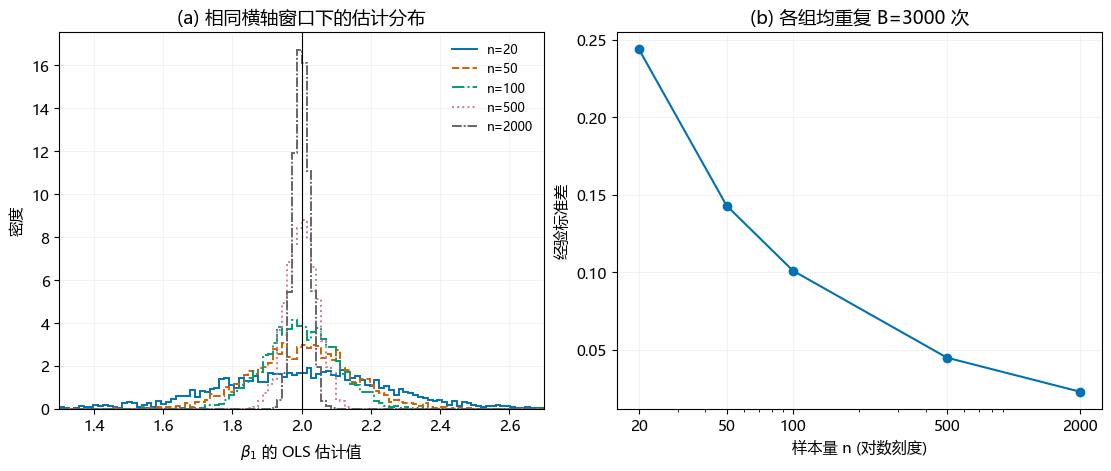

In [12]:
#| label: fig-mc-nb-ols-consistency
#| fig-cap: "OLS 一致性：不同样本量下的估计分布与经验标准差。"
# 一致性：共享显示窗口，密度以全部 B 次结果为分母，不重新归一化截尾样本。
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
edges = np.linspace(1.3, 2.7, 101)
for index, sample_size in enumerate(sample_sizes):
    estimates = ols_results[sample_size]
    counts, edges = np.histogram(estimates, bins=edges)
    axes[0].stairs(counts / len(estimates) / np.diff(edges), edges,
                   label=f'n={sample_size}', color=colors[index],
                   linestyle=line_styles[index], linewidth=1.4)
axes[0].axvline(2, color='black', linewidth=.8)
axes[0].set(xlabel=r'$\beta_{1}$ 的 OLS 估计值', ylabel='密度', xlim=(1.3, 2.7),
            title='(a) 相同横轴窗口下的估计分布')
axes[0].legend(frameon=False, fontsize=9)
axes[1].plot(ols_summary['n'], ols_summary['empirical_sd'],
             marker='o', color=colors[0], label='经验标准差')
axes[1].set(xscale='log', xlabel='样本量 n (对数刻度)', ylabel='经验标准差',
            title='(b) 各组均重复 B=3000 次')
axes[1].set_xticks(sample_sizes, [str(value) for value in sample_sizes])
for axis in axes:
    axis.grid(alpha=.15)
plt.show()

样本量由 20 增至 2000 时，估计值的经验标准差由约 0.244 降至 0.023，分布也更集中于真值 2 附近。这里增加的是每次回归使用的观测数，各组重复次数均为 3000。有限组样本量的比较展示了一致性所预期的变化，但不证明其极限性质。

### IV：内生性与弱工具变量 {.unnumbered}

本例生成 $Y=\beta X+\gamma W+u$ 和 $X=\pi Z+\delta u+v$。其中 $X$ 是需要估计其影响的解释变量，$W$ 是外生控制变量，$Z$ 是工具变量，$u$、$v$ 是两项扰动。$Z,W,u,v$ 相互独立且均服从标准正态分布，不同观测之间也独立。参数真值为 $\beta=\gamma=1$。

$\delta$ 控制 $X$ 中来自 $u$ 的部分，非零时使 $X$ 与结果方程的扰动相关，产生内生性。$\pi$ 控制工具变量与 $X$ 的相关性。$Z$ 与 $u$ 独立且不直接进入结果方程，IV 利用 $Z$ 引起的 $X$ 变动估计 $\beta$。每个样本同时计算 OLS 与 IV，便于比较。

#### 改变内生性 {.unnumbered}

固定 $n=500$、$B=1200$ 和 $\pi=1$，改变 $\delta$。下面先定义生成与估计函数，再比较两种估计均值。

In [13]:
def iv_mc(
    n=500,
    B=1200,
    beta=1.0,
    gamma=1.0,
    pi=1.0,
    delta=0.5,
    seed=SEED
):
    rng = np.random.default_rng(seed)
    ols_hat = np.empty(B)
    iv_hat = np.empty(B)

    for b in range(B):
        z = rng.normal(0, 1, n)
        w = rng.normal(0, 1, n)
        u = rng.normal(0, 1, n)
        v = rng.normal(0, 1, n)

        x = pi * z + delta * u + v
        y = beta * x + gamma * w + u

        X_ols = sm.add_constant(np.column_stack([x, w]))
        ols = sm.OLS(y, X_ols).fit()
        ols_hat[b] = ols.params[1]

        # 2SLS 的解释变量为常数项、X、W，工具变量为常数项、Z、W。
        X_iv = sm.add_constant(np.column_stack([x, w]))
        Z_iv = sm.add_constant(np.column_stack([z, w]))
        iv = IV2SLS(y, X_iv, instrument=Z_iv).fit()
        iv_hat[b] = iv.params[1]

    return pd.DataFrame({"OLS": ols_hat, "IV": iv_hat})

In [14]:
delta_grid = [0.0, 0.2, 0.5, 0.8]
endogeneity_results = {}

for d in delta_grid:
    endogeneity_results[d] = iv_mc(
        n=500, B=1200, pi=1.0, delta=d, seed=SEED + int(d * 1000)
    )

summary_b1 = []
for d, df in endogeneity_results.items():
    for method in ["OLS", "IV"]:
        vals = df[method].to_numpy()
        summary_b1.append({
            "delta": d,
            "method": method,
            "mean": vals.mean(),
            "bias": vals.mean() - 1.0,
            "sd": vals.std(ddof=1),
            "rmse": np.sqrt(np.mean((vals - 1.0)**2)),
        })
show_table(pd.DataFrame(summary_b1), {'delta': '内生性参数 δ', 'method': '估计方法', 'mean': '估计均值', 'bias': 'MC 偏差', 'sd': '经验标准差', 'rmse': '均方根误差'})

内生性参数 δ,估计方法,估计均值,MC 偏差,经验标准差,均方根误差
0.000,OLS,0.999,-0.001,0.032,0.032
0.000,IV,0.999,-0.001,0.046,0.046
0.200,OLS,1.099,0.099,0.031,0.104
0.200,IV,1.001,0.001,0.045,0.045
0.500,OLS,1.223,0.223,0.028,0.225
0.500,IV,0.999,-0.001,0.044,0.044
0.800,OLS,1.303,0.303,0.024,0.303
0.800,IV,0.997,-0.003,0.044,0.044


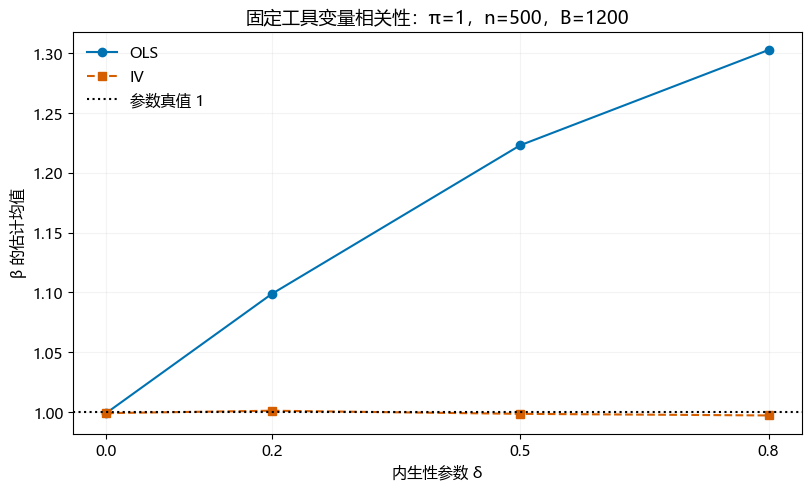

In [15]:
#| label: fig-mc-nb-iv-endogeneity
#| fig-cap: "固定工具变量相关性，比较内生性变化下的 OLS 与 IV 均值。"
# 内生性：比较同样本 OLS/IV 的估计均值，不添加未经解释的总体置信区间。
fig, axis = plt.subplots(figsize=(8, 4.8), layout='constrained')
for method, color, marker, style in [('OLS', colors[0], 'o', '-'),
                                      ('IV', colors[1], 's', '--')]:
    means = [endogeneity_results[value][method].mean() for value in delta_grid]
    axis.plot(delta_grid, means, color=color, marker=marker,
               linestyle=style, label=method)
axis.axhline(1, color='black', linestyle=':', label='参数真值 1')
axis.set(xlabel='内生性参数 δ', ylabel='β 的估计均值',
         title='固定工具变量相关性：π=1，n=500，B=1200')
axis.set_xticks(delta_grid)
axis.legend(frameon=False)
axis.grid(alpha=.15)
plt.show()

随着 $\delta$ 从 0 增至 0.8，OLS 估计均值由约 0.999 升至 1.303，而 IV 估计均值仍接近真值 1。表中的均方根误差是估计误差平方平均值的平方根，同时反映偏差和离散程度。本组实验的工具变量较强，IV 对内生性的处理较稳定，但这不意味着 IV 在有限样本中必然无偏。

#### 减弱工具变量相关性 {.unnumbered}

固定 $\delta=0.5$，依次降低 $\pi$，其余设置不变。下图为经验累积分布 (ECDF)：横轴给定一个估计值，纵轴表示不超过该值的估计结果所占比例。两图都以全部 1200 次估计为分母，左图保留极端估计，右图放大真值附近。

In [16]:
pi_grid = [1.0, 0.5, 0.2, 0.05]
weak_results = {}

for pival in pi_grid:
    weak_results[pival] = iv_mc(
        n=500, B=1200, pi=pival, delta=0.5,
        seed=SEED + int(pival * 10000)
    )

summary_b2 = []
for pival, df in weak_results.items():
    vals = df["IV"].to_numpy()
    summary_b2.append({
        "pi": pival,
        "mean_iv": vals.mean(),
        "bias_iv": vals.mean() - 1.0,
        "sd_iv": vals.std(ddof=1),
        "rmse_iv": np.sqrt(np.mean((vals - 1.0)**2)),
        "q01": np.quantile(vals, 0.01),
        "q99": np.quantile(vals, 0.99),
    })

show_table(pd.DataFrame(summary_b2), {'pi': '工具变量参数 π', 'mean_iv': 'IV 估计均值', 'bias_iv': 'MC 偏差', 'sd_iv': '经验标准差', 'rmse_iv': '均方根误差', 'q01': '1% 分位数', 'q99': '99% 分位数'})

工具变量参数 π,IV 估计均值,MC 偏差,经验标准差,均方根误差,1% 分位数,99% 分位数
1.000,0.999,-0.001,0.046,0.046,0.887,1.101
0.500,0.995,-0.005,0.092,0.092,0.743,1.188
0.200,0.960,-0.040,0.283,0.285,0.133,1.475
0.050,2.123,1.123,27.982,27.993,-13.637,23.416


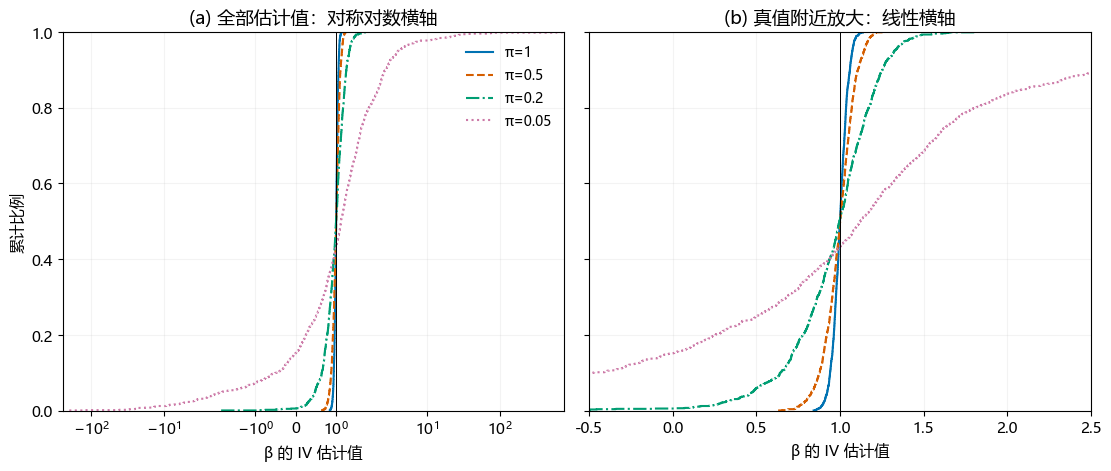

In [17]:
#| label: fig-mc-nb-iv-weak
#| fig-cap: "弱工具变量的完整经验分布及局部放大。"
# 弱工具变量：经验分布的分母始终为全部 1200 次，左图保留全部极端值。
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, layout='constrained')
for index, instrument_strength in enumerate(pi_grid):
    estimates = np.sort(weak_results[instrument_strength]['IV'].to_numpy())
    probabilities = np.arange(1, len(estimates) + 1) / len(estimates)
    for axis in axes:
        axis.step(estimates, probabilities, where='post', color=colors[index],
                   linestyle=line_styles[index], linewidth=1.5,
                   label=f'π={instrument_strength:g}')
for axis in axes:
    axis.axvline(1, color='black', linewidth=.7)
    axis.set(xlabel='β 的 IV 估计值', ylim=(0, 1))
    axis.grid(alpha=.15)
axes[0].set_xscale('symlog', linthresh=2)
axes[0].set(title='(a) 全部估计值：对称对数横轴', ylabel='累计比例')
axes[1].set(title='(b) 真值附近放大：线性横轴', xlim=(-.5, 2.5))
axes[0].legend(frameon=False, fontsize=10)
plt.show()

当 $\pi=1$ 时，IV 估计值的 1% 与 99% 分位数约为 0.887 和 1.101。降至 $\pi=0.05$ 后，两者约为 -13.637 和 23.416，极端估计明显增多。此时均值容易受少数结果影响，需要结合完整分布与分位数判断估计的稳定程度。

In [18]:
#| include: false
from pathlib import Path
import os
export_dir = OUTPUT / 'case1'
export_dir.mkdir(parents=True, exist_ok=True)
arrays = {'unbiased': bhat_100}
arrays.update({f'consistency_{sample_size}': values for sample_size, values in ols_results.items()})
arrays.update({f'endogeneity_{value:g}': results.to_numpy() for value, results in endogeneity_results.items()})
arrays.update({f'weak_{value:g}': results.to_numpy() for value, results in weak_results.items()})
np.savez_compressed(export_dir / 'estimates.npz', **arrays)
ols_summary.to_csv(export_dir / 'ols-consistency.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(summary_b1).to_csv(export_dir / 'iv-endogeneity.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(summary_b2).to_csv(export_dir / 'iv-weak.csv', index=False, encoding='utf-8-sig')

In [19]:
#| include: false
case_results['case1'] = {'mean': float(bhat_100.mean()), 'bias': float(bhat_100.mean()-2), 'arrays': len(arrays)}

## 案例二：项目估值 {.unnumbered #sec-mc-nb-valuation}

[返回正文：案例二](../../lectures/monte-carlo.qmd#sec-mc-valuation)。

企业选择价格后，由年度需求冲击生成市场份额，再沿销量、收入和现金流关系计算项目 NPV。价格是决策变量，需求冲击和贴现率是不确定性因素，市场份额及 NPV 是模型计算结果。

本例期限为 10 年，年度潜在市场规模为 100 万件，初始投资 3500 万元，年度固定支出 600 万元，现金流转化比例为 0.28。需求冲击标准差为 0.55。贴现率设为 $r=0.05+0.07X_{r}$，其中 $X_{r}\sim Beta(3,4)$。每个情景使用一个贴现率，需求冲击按年独立抽取。金额计算使用元，NPV 表和图使用百万元。

实际应用中，市场规模可结合行业资料与市场调研估算，现金流比例与固定支出需参考财务记录，价格敏感性则需要历史销售或试销资料支持。本页参数为教学设定，不是这些资料的实证估计。

### 经营关系与参数 {.unnumbered}

将价格 $p$ 固定在规划期内，各年的市场份额按下式生成：

$$
s_{t}=\Lambda\!\left[\alpha-\beta\log(p/\bar p)+\varepsilon_{t}\right],
\qquad \Lambda(x)=\frac{e^{x}}{1+e^{x}}.
$$ {#eq-mc-nb-valuation-share}

其中，$\bar p=100$ 为市场参考价格，$\alpha=-0.4$ 决定参考价格且无冲击时的份额水平，$\beta=2.2$ 控制价格敏感性，$\varepsilon_{t}\sim N(0,0.55^{2})$ 为年度需求冲击。价格提高会压低份额，logistic 变换则保证份额在 0 与 1 之间。代码中的 `p_ref` 和 `beta_price` 分别对应 $\bar p$ 和 $\beta$。

市场份额乘以年度潜在市场规模 $Q_{0}$ 得到销量，再乘以价格得到收入。自由现金流为 $FCF_{t}=mpQ_{0}s_{t}-F$，其中 $m=0.28$ 为现金流转化比例，$F$ 为年度固定支出。NPV 为未来十年各年末现金流的现值之和减去初始投资 $I_{0}$：

$$
NPV=-I_{0}+\sum_{t=1}^{10}\frac{FCF_{t}}{(1+r)^{t}}.
$$ {#eq-mc-nb-valuation-npv}

`simulate_project` 在函数内初始化发生器。比较价格时使用相同种子和相同的抽样步骤，使各方案面对同一批需求冲击和贴现率。

In [20]:
SEED = 20261001

# 教学参数
T = 10
Q0 = 1_000_000
p_ref = 100.0
alpha = -0.4
beta_price = 2.2
sigma_eps = 0.55

m = 0.28
F = 6_000_000
I0 = 35_000_000

a_r = 3.0
b_r = 4.0
r_min = 0.05
r_max = 0.12

B = 20_000

In [21]:
def logistic(x):
    return 1 / (1 + np.exp(-x))

def simulate_project(
    p,
    B=B,
    seed=SEED,
    Q0=Q0,
    alpha=alpha,
    beta_price=beta_price,
    p_ref=p_ref,
    sigma_eps=sigma_eps,
    m=m,
    F=F,
    I0=I0,
    T=T,
    a_r=a_r,
    b_r=b_r,
    r_min=r_min,
    r_max=r_max,
):
    rng = np.random.default_rng(seed)
    eps = rng.normal(0, sigma_eps, size=(B, T))
    share = logistic(
        alpha - beta_price * np.log(p / p_ref) + eps
    )
    quantity = share * Q0
    sales = p * quantity
    fcf = m * sales - F

    x_r = rng.beta(a_r, b_r, size=B)
    discount_rate = r_min + (r_max - r_min) * x_r

    years = np.arange(1, T + 1)
    df = (1 + discount_rate[:, None]) ** years
    npv = -I0 + np.sum(fcf / df, axis=1)

    # 贴现加权份额使用各情景自身的贴现率，不改变原 NPV 计算。
    discount_weight = (1 + discount_rate[:, None]) ** (-years)
    weighted_share = np.sum(share * discount_weight, axis=1) / discount_weight.sum(axis=1)

    return {
        "weighted_share": weighted_share,
        "npv": npv,
        "share": share,
        "avg_share": share.mean(axis=1),
        "quantity": quantity,
        "sales": sales,
        "fcf": fcf,
        "discount_rate": discount_rate,
    }

def annuity_factor(r, T=T):
    return (1 - (1 + r) ** (-T)) / r

def required_share_for_npv_zero(p, r):
    af = annuity_factor(r)
    annual_fcf_required = I0 / af
    annual_sales_contribution_required = annual_fcf_required + F
    return annual_sales_contribution_required / (m * p * Q0)

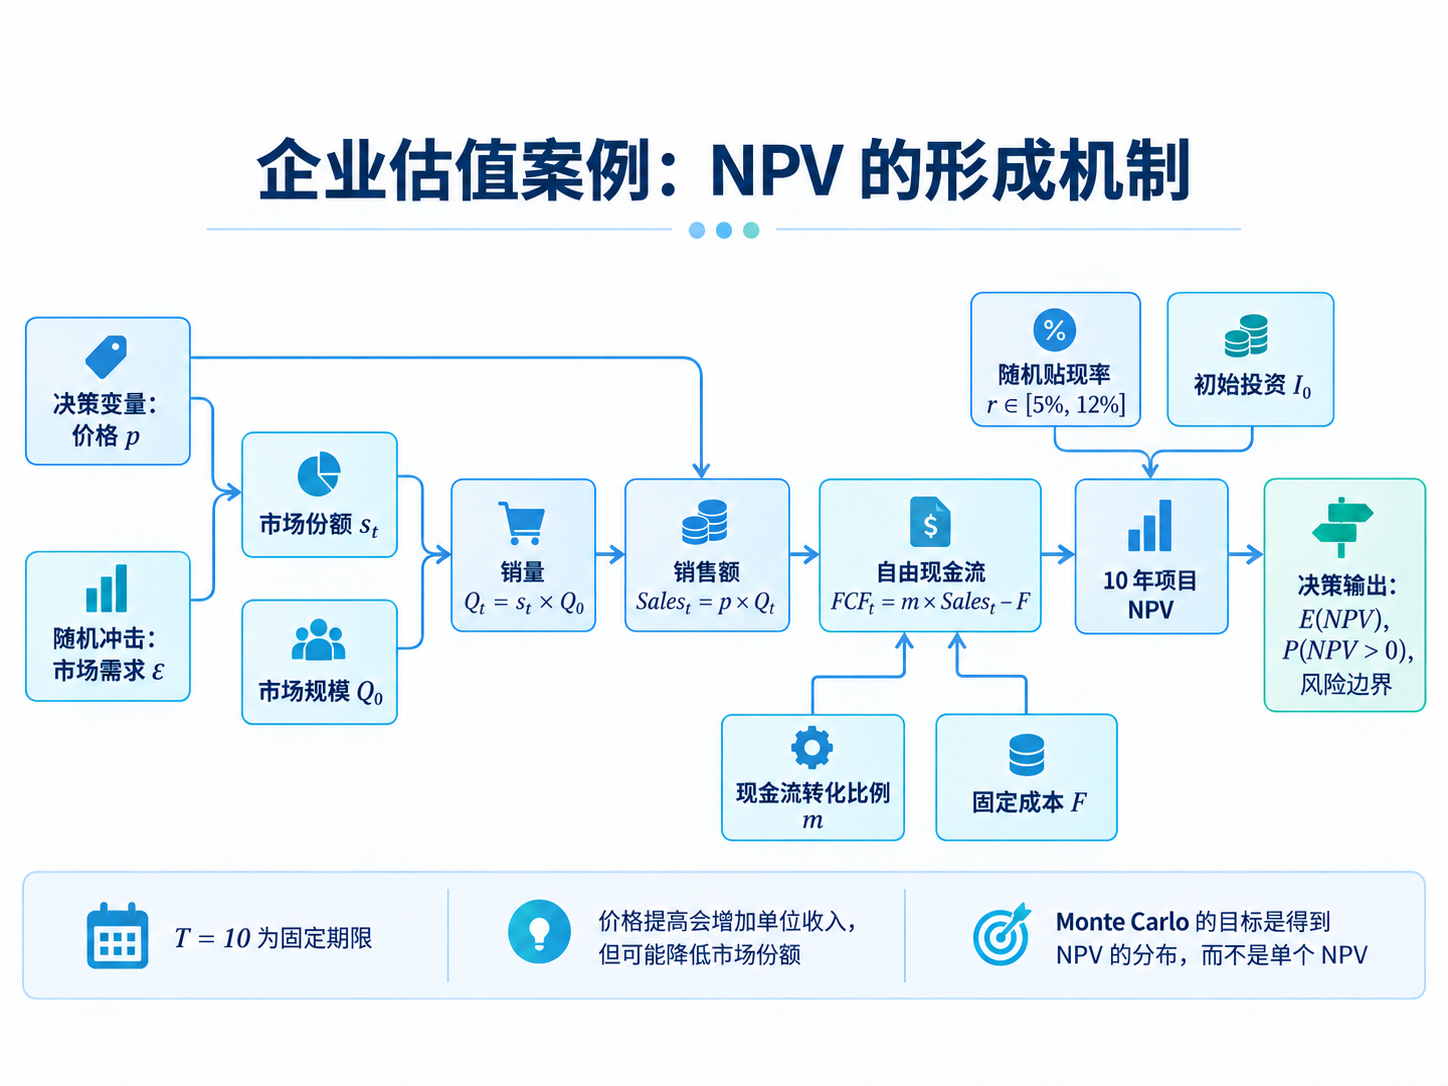

In [22]:
#| label: fig-mc-nb-valuation-mechanism
#| fig-cap: "经营关系：现金流转化比例与固定支出作用于自由现金流。"
display(Image(filename=str(ROOT / 'figs/raw/mc-valuation-fig01-mechanism-corrected-20261017-225145.png')))

### 从一个情景到 NPV 分布 {.unnumbered}

在价格 80 元下生成 20000 个十年经营情景。核心数组每行对应一个情景，每列对应一年。沿年份折现汇总现金流后，每个情景得到一个 NPV。均值说明预期价值，正 NPV 比例与 5% 分位数分别反映满足投资标准的概率及下行损失。

In [23]:
base_p = 80.0
base = simulate_project(base_p)

summary = pd.Series({
    "Price": base_p,
    "Mean NPV (million)": base["npv"].mean() / 1e6,
    "Median NPV (million)": np.median(base["npv"]) / 1e6,
    "P(NPV > 0)": np.mean(base["npv"] > 0),
    "NPV 5% quantile (million)": np.quantile(base["npv"], 0.05) / 1e6,
    "NPV 95% quantile (million)": np.quantile(base["npv"], 0.95) / 1e6,
    "Mean market share": base["share"].mean(),
    "Mean discounted market share": base["weighted_share"].mean(),
    "Mean discount rate": base["discount_rate"].mean(),
})

baseline_display = summary.loc[['Price', 'Mean NPV (million)', 'P(NPV > 0)',
                                'NPV 5% quantile (million)']].copy()
baseline_display.loc['P(NPV > 0)'] *= 100
baseline_display.index = ['产品价格 (元)', '平均 NPV (百万元)',
                          'NPV 为正的概率 (%)', 'NPV 的 5% 分位数 (百万元)']
show_table(baseline_display.rename_axis('指标').rename('数值').reset_index())

指标,数值
产品价格 (元),80.000
平均 NPV (百万元),3.188
NPV 为正的概率 (%),68.365
NPV 的 5% 分位数 (百万元),-7.493


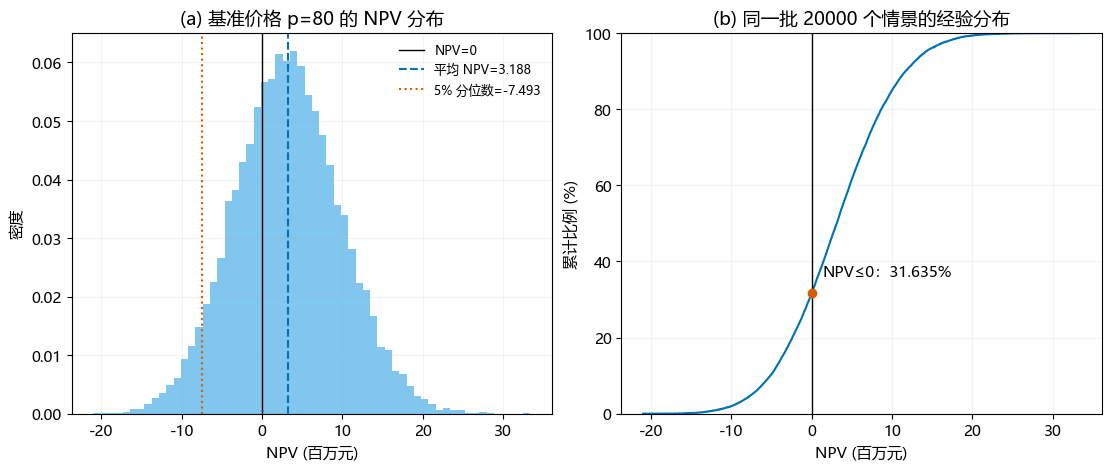

In [24]:
#| label: fig-mc-nb-valuation-npv
#| fig-cap: "价格 80 元下的 NPV 分布与经验累积分布。"
# BASELINE_FIGURE
plt.rcParams.update({'font.family': 'Microsoft YaHei', 'font.size': 11,
                     'axes.unicode_minus': False})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
values = base['npv'] / 1e6
axes[0].hist(values, bins=60, density=True, color='#56B4E9', alpha=.75)
axes[0].axvline(0, color='black', linewidth=1, label='NPV=0')
axes[0].axvline(values.mean(), color='#0072B2', linestyle='--',
                label=f'平均 NPV={values.mean():.3f}')
axes[0].axvline(np.quantile(values, .05), color='#D55E00', linestyle=':',
                label=f'5% 分位数={np.quantile(values, .05):.3f}')
axes[0].set(title='(a) 基准价格 p=80 的 NPV 分布', xlabel='NPV (百万元)', ylabel='密度')
axes[0].legend(frameon=False, fontsize=9)
sorted_values = np.sort(values)
probabilities = np.arange(1, B + 1) / B
axes[1].step(sorted_values, probabilities * 100, where='post', color='#0072B2')
nonpositive = np.mean(values <= 0) * 100
axes[1].axvline(0, color='black', linewidth=1)
axes[1].scatter([0], [nonpositive], color='#D55E00', zorder=3)
axes[1].annotate(f'NPV≤0：{nonpositive:.3f}%', xy=(0, nonpositive),
                 xytext=(8, 12), textcoords='offset points')
axes[1].set(title='(b) 同一批 20000 个情景的经验分布',
            xlabel='NPV (百万元)', ylabel='累计比例 (%)', ylim=(0, 100))
for axis in axes:
    axis.grid(alpha=.15)
plt.show()

平均 NPV 约为 3.188 百万元，正 NPV 的情景占 68.365%，但 NPV 的 5% 分位数为 -7.493 百万元。图中仍有相当一部分情景落在零的左侧，因此平均价值为正并不意味着下行损失可以忽略。正 NPV 表示该情景下未来现金流现值超过初始投资，满足净现值投资标准。

### 从 NPV 分布进入价格决策 {.unnumbered}

候选价格从 55 到 160 元，间隔 5 元。每个价格使用同样的模拟次数和随机输入，以便比较价格改变后的经营结果。下表同时列出平均 NPV、正 NPV 概率和 NPV 的 5% 分位数，分别对应预期价值、满足投资标准的可能性和下行风险。

In [25]:
price_grid = np.arange(55, 161, 5)

valuation_cache = {float(price): simulate_project(price) for price in price_grid}
rows = []
for p in price_grid:
    result = valuation_cache[float(p)]
    rows.append({
        "price": p,
        "mean_npv_million": result["npv"].mean() / 1e6,
        "median_npv_million": np.median(result["npv"]) / 1e6,
        "prob_positive": np.mean(result["npv"] > 0),
        "npv_5pct_million": np.quantile(result["npv"], 0.05) / 1e6,
        "mean_share": result["share"].mean(),
    })

price_results = pd.DataFrame(rows)

show_table(price_results[['price', 'mean_npv_million', 'prob_positive', 'npv_5pct_million']],
           {'price': '价格 (元)', 'mean_npv_million': '平均 NPV (百万元)',
            'prob_positive': 'NPV 为正的概率 (%)', 'npv_5pct_million': '5% 分位数 (百万元)'},
           percentages=['prob_positive'])

价格 (元),平均 NPV (百万元),NPV 为正的概率 (%),5% 分位数 (百万元)
55,-2.620,25.885,-9.289
60,-0.412,46.425,-8.003
65,1.202,59.120,-7.270
70,2.294,65.585,-6.985
75,2.934,68.225,-7.075
80,3.188,68.365,-7.493
85,3.114,66.845,-8.159
90,2.766,64.180,-8.994
95,2.191,60.790,-9.976
100,1.430,56.340,-11.086


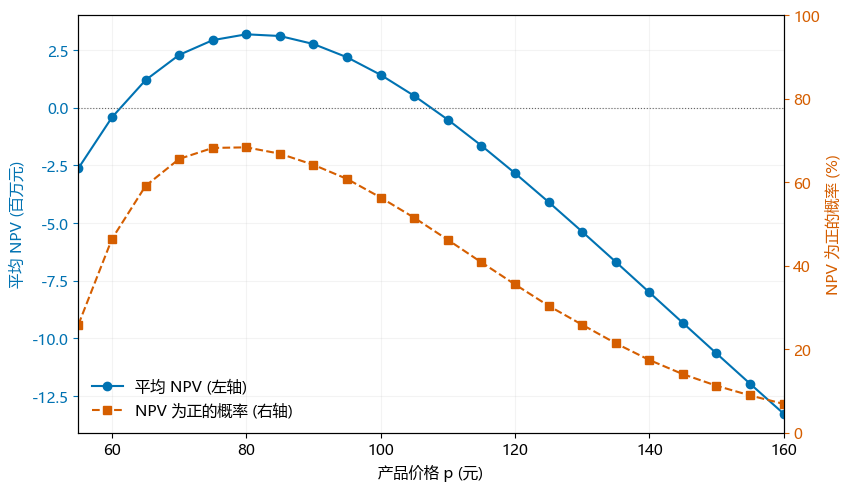

In [26]:
#| label: fig-mc-nb-valuation-prices
#| fig-cap: "候选价格下的平均 NPV 与正 NPV 概率。左轴为平均 NPV (百万元)，右轴为正 NPV 概率 (%)，虚线水平线表示左轴 NPV 为零。两条曲线的交点没有经济含义。"
fig, value_axis = plt.subplots(figsize=(8.4, 4.8), layout='constrained')
probability_axis = value_axis.twinx()
value_line, = value_axis.plot(price_results['price'], price_results['mean_npv_million'],
                            marker='o', color='#0072B2', label='平均 NPV (左轴)')
probability_line, = probability_axis.plot(price_results['price'], price_results['prob_positive'] * 100,
                                        marker='s', linestyle='--', color='#D55E00',
                                        label='NPV 为正的概率 (右轴)')
value_axis.axhline(0, color='#666666', linewidth=.8, linestyle=':')
value_axis.set(xlabel='产品价格 p (元)', ylabel='平均 NPV (百万元)',
               xlim=(price_grid.min(), price_grid.max()))
probability_axis.set(ylabel='NPV 为正的概率 (%)', ylim=(0, 100))
value_axis.tick_params(axis='y', colors='#0072B2')
probability_axis.tick_params(axis='y', colors='#D55E00')
value_axis.yaxis.label.set_color('#0072B2')
probability_axis.yaxis.label.set_color('#D55E00')
value_axis.grid(alpha=.15)
value_axis.legend(handles=[value_line, probability_line], loc='lower left', frameon=False)
plt.show()

本组网格中，80 元的平均 NPV 和正 NPV 概率最高，70 元的 5% 分位数最高。三项指标未必指向同一方案。这里没有另外指定企业风险约束，不给出唯一最优价格。

### NPV = 0 的决策边界 {.unnumbered}

给定价格和贴现率，项目需要达到多大的市场份额，才能使 NPV 不低于零？令 $A(r,T)=\sum_{t=1}^{T}(1+r)^{-t}$ 为年金现值因子。当每年的份额相同，使 NPV 恰好为零的临界份额为

$$
s^{*}(p,r)=\frac{F+I_{0}/A(r,T)}{mpQ_{0}}.
$$ {#eq-mc-nb-valuation-threshold}

年度份额随冲击变化时，应按贴现系数计算加权平均份额 $\widetilde{s}(r)$，才能与同一情景的投资门槛比较：

$$
\widetilde{s}(r)=\frac{\sum_{t=1}^{T}s_{t}(1+r)^{-t}}{A(r,T)},
\qquad
NPV=mpQ_{0}A(r,T)\left[\widetilde{s}(r)-s^{*}(p,r)\right].
$$ {#eq-mc-nb-valuation-weighted-share}

前面的乘数均为正，因此加权份额高于门槛时 NPV 为正，低于门槛时 NPV 为负。这里各年份的高份额出现得越早，对现值的贡献越大，简单平均份额不能代替贴现加权份额。

下图边界带来自贴现率上下限，不是置信区间。左图每价选 250 个情景显示，右图显示基准价格的全部 20000 个情景。

In [27]:
p_boundary = np.linspace(55, 160, 400)

s_low_r = required_share_for_npv_zero(p_boundary, r_min)
s_high_r = required_share_for_npv_zero(p_boundary, r_max)

# 贴现率均值对应的中心边界
mean_r = r_min + (r_max - r_min) * (a_r / (a_r + b_r))
s_mean_r = required_share_for_npv_zero(p_boundary, mean_r)

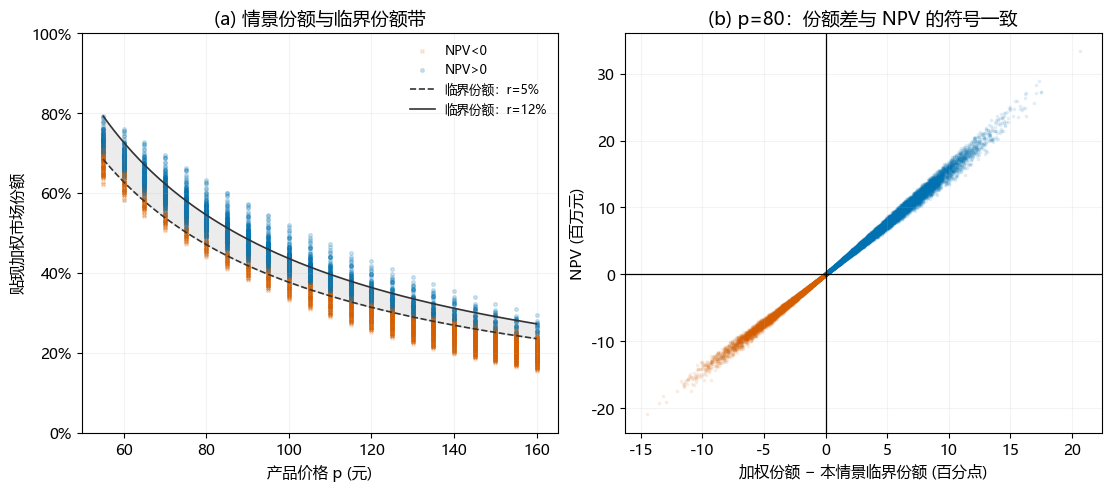

In [28]:
#| label: fig-mc-nb-valuation-boundary
#| fig-cap: "贴现加权份额与 NPV=0 门槛的对应关系。"
# WEIGHTED_BOUNDARY_FIGURE
from matplotlib.ticker import PercentFormatter
display_rng = np.random.default_rng(SEED + 98765)
display_indices = display_rng.choice(B, size=250, replace=False)
sample_rows = []
for price in price_grid:
    scenario = simulate_project(price, B=B, seed=SEED)
    sample_rows.append(pd.DataFrame({
        'price': price, 'weighted_share': scenario['weighted_share'][display_indices],
        'discount_rate': scenario['discount_rate'][display_indices],
        'npv': scenario['npv'][display_indices],
    }))
scatter_df = pd.concat(sample_rows, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
for positive, color, marker, label in [(False, '#D55E00', 'x', 'NPV<0'),
                                       (True, '#0072B2', 'o', 'NPV>0')]:
    selected = scatter_df['npv'] > 0 if positive else scatter_df['npv'] < 0
    axes[0].scatter(scatter_df.loc[selected, 'price'], scatter_df.loc[selected, 'weighted_share'],
                     color=color, marker=marker, s=7, alpha=.18, label=label)
axes[0].fill_between(p_boundary, s_low_r, s_high_r, color='.5', alpha=.15)
axes[0].plot(p_boundary, s_low_r, color='.2', linestyle='--', linewidth=1.2, label='临界份额：r=5%')
axes[0].plot(p_boundary, s_high_r, color='.2', linestyle='-', linewidth=1.2, label='临界份额：r=12%')
axes[0].set(xlabel='产品价格 p (元)', ylabel='贴现加权市场份额', ylim=(0, 1),
            title='(a) 情景份额与临界份额带')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(frameon=False, fontsize=9, loc='upper right')
critical_base = required_share_for_npv_zero(base_p, base['discount_rate'])
share_gap = base['weighted_share'] - critical_base
for positive, color in [(False, '#D55E00'), (True, '#0072B2')]:
    selected = base['npv'] > 0 if positive else base['npv'] < 0
    axes[1].scatter(share_gap[selected] * 100, base['npv'][selected] / 1e6,
                     s=3, alpha=.08, color=color)
axes[1].axvline(0, color='black', linewidth=.9)
axes[1].axhline(0, color='black', linewidth=.9)
axes[1].set(title='(b) p=80：份额差与 NPV 的符号一致',
            xlabel='加权份额 − 本情景临界份额 (百分点)', ylabel='NPV (百万元)')
for axis in axes:
    axis.grid(alpha=.15)
plt.show()

::: {.callout-note collapse="true" title="补充分析：经营条件变差后，项目是否仍值得投资"}

保持价格为 80 元，分别降低市场规模、提高固定支出和调整贴现率分布，其余条件不变。三种不利条件分别进行模拟，不同时叠加，以便分辨各自的影响。

In [29]:
def scenario_summary(name, **kwargs):
    result = simulate_project(base_p, **kwargs)
    return {
        "scenario": name,
        "mean_npv_million": result["npv"].mean() / 1e6,
        "prob_positive": np.mean(result["npv"] > 0),
        "npv_5pct_million": np.quantile(result["npv"], 0.05) / 1e6,
    }

stress_results = pd.DataFrame([
    scenario_summary("Baseline"),
    scenario_summary("Market size -15%", Q0=Q0 * 0.85),
    scenario_summary("Fixed cost +20%", F=F * 1.20),
    scenario_summary(
        "Higher discount rates",
        r_min=0.08,
        r_max=0.12,
        a_r=3.0,
        b_r=2.0,
    ),
])


stress_display = stress_results.replace({'Baseline': '基准情景', 'Market size -15%': '市场规模下降 15%',
                                         'Fixed cost +20%': '固定支出增加 20%',
                                         'Higher discount rates': '贴现率整体提高'})
show_table(stress_display, {'scenario': '情景', 'mean_npv_million': '平均 NPV (百万元)',
                           'prob_positive': 'NPV 为正的概率 (%)',
                           'npv_5pct_million': '5% 分位数 (百万元)'}, percentages=['prob_positive'])

情景,平均 NPV (百万元),NPV 为正的概率 (%),5% 分位数 (百万元)
基准情景,3.188,68.365,-7.493
市场规模下降 15%,-8.592,6.120,-17.537
固定支出增加 20%,-4.881,22.285,-15.382
贴现率整体提高,-0.665,45.135,-10.112


本例中，市场规模下降 15% 后，平均 NPV 由约 3.188 降至 -8.592 百万元，正 NPV 概率降至 6.120%。固定支出增加或贴现率提高也使平均 NPV 转为负值。这说明基准情景的正平均价值依赖经营条件，增加模拟次数并不能消除这些风险。

:::

In [30]:
#| include: false
diagnostics = pd.Series({
    "share_min": base["share"].min(),
    "share_max": base["share"].max(),
    "discount_rate_min": base["discount_rate"].min(),
    "discount_rate_max": base["discount_rate"].max(),
    "has_positive_npv": bool(np.any(base["npv"] > 0)),
    "has_negative_npv": bool(np.any(base["npv"] < 0)),
})

In [31]:
#| include: false
"""价格决策指标与贴现加权市场份额的可执行核验。"""
from pathlib import Path
import json
import os

export_dir = OUTPUT / 'valuation'
export_dir.mkdir(parents=True, exist_ok=True)
years = np.arange(1, T + 1)
valuation_scenarios = {}
decision_rows = []
validation_rows = []
for price in price_grid:
    scenario = valuation_cache[float(price)]
    discount = (1 + scenario['discount_rate'][:, None]) ** (-years)
    annuity = discount.sum(axis=1)
    weighted_share = (scenario['share'] * discount).sum(axis=1) / annuity
    critical_share = (F + I0 / annuity) / (m * price * Q0)
    reconstructed_npv = -I0 + (m * price * Q0 * weighted_share - F) * annuity
    gap_npv = m * price * Q0 * annuity * (weighted_share - critical_share)
    original_npv = scenario['npv']
    direct_positive = original_npv > 0
    weighted_positive = weighted_share > critical_share
    arithmetic_positive = scenario['avg_share'] > critical_share
    identity_error = np.abs(original_npv - reconstructed_npv).max()
    assert np.allclose(original_npv, reconstructed_npv, rtol=1e-12, atol=1e-6)
    assert np.allclose(original_npv, gap_npv, rtol=1e-12, atol=1e-6)
    assert np.array_equal(direct_positive, weighted_positive)
    assert np.array_equal(annuity > 0, np.ones(B, dtype=bool))
    assert np.allclose(annuity, annuity_factor(scenario['discount_rate']), rtol=1e-13, atol=1e-13)
    assert np.allclose(critical_share, required_share_for_npv_zero(price, scenario['discount_rate']))
    low = required_share_for_npv_zero(price, r_min)
    high = required_share_for_npv_zero(price, r_max)
    assert low < high
    assert np.all(direct_positive[weighted_share > high])
    assert not np.any(direct_positive[weighted_share < low])
    valuation_scenarios[price] = {
        'npv': original_npv, 'weighted_share': weighted_share,
        'avg_share': scenario['avg_share'], 'critical_share': critical_share,
        'discount_rate': scenario['discount_rate'],
    }
    decision_rows.append({
        'price': price, 'mean_npv_million': original_npv.mean() / 1e6,
        'median_npv_million': np.median(original_npv) / 1e6,
        'prob_positive': direct_positive.mean(),
        'npv_5pct_million': np.quantile(original_npv, .05) / 1e6,
        'mean_mcse_million': original_npv.std(ddof=1) / np.sqrt(B) / 1e6,
        'mean_share': scenario['share'].mean(),
        'zero_npv_count': int((original_npv == 0).sum()),
    })
    validation_rows.append({
        'price': price, 'B': B, 'max_identity_error': identity_error,
        'weighted_sign_mismatches': int((direct_positive != weighted_positive).sum()),
        'arithmetic_sign_mismatches': int((direct_positive != arithmetic_positive).sum()),
    })

decision_results = pd.DataFrame(decision_rows)
weighted_checks = pd.DataFrame(validation_rows)
decision_results.to_csv(export_dir / 'price-results.csv', index=False, encoding='utf-8-sig')
weighted_checks.to_csv(export_dir / 'weighted-checks.csv', index=False, encoding='utf-8-sig')
summary.rename('value').to_csv(export_dir / 'baseline-summary.csv', encoding='utf-8-sig')
stress_results.to_csv(export_dir / 'stress-results.csv', index=False, encoding='utf-8-sig')
np.savez_compressed(export_dir / 'scenarios.npz', prices=price_grid,
    npv=np.stack([valuation_scenarios[price]['npv'] for price in price_grid]),
    weighted_share=np.stack([valuation_scenarios[price]['weighted_share'] for price in price_grid]),
    arithmetic_share=np.stack([valuation_scenarios[price]['avg_share'] for price in price_grid]),
    critical_share=np.stack([valuation_scenarios[price]['critical_share'] for price in price_grid]),
    discount_rate=np.stack([valuation_scenarios[price]['discount_rate'] for price in price_grid]))

# 构造简单平均完全相同、但较高份额出现时间不同的两条记录。
example_rate = .08
example_price = 80.
example_discount = (1 + example_rate) ** (-years)
examples = []
for name, shares in [('较高份额在前五年', np.r_[np.full(5, .8), np.full(5, .2)]),
                      ('较高份额在后五年', np.r_[np.full(5, .2), np.full(5, .8)])]:
    weighted = np.sum(shares * example_discount) / example_discount.sum()
    value = -I0 + np.sum((m * example_price * Q0 * shares - F) * example_discount)
    examples.append({'example': name, 'arithmetic_share': shares.mean(),
        'weighted_share': weighted, 'critical_share': required_share_for_npv_zero(example_price, example_rate),
        'npv_million': value / 1e6})
counterexample = pd.DataFrame(examples)
assert np.isclose(counterexample.arithmetic_share.iloc[0], counterexample.arithmetic_share.iloc[1])
assert counterexample.npv_million.iloc[0] > 0 and counterexample.npv_million.iloc[1] < 0
counterexample.to_csv(export_dir / 'same-average-counterexample.csv', index=False, encoding='utf-8-sig')

# 在门槛及两侧做确定性检查，舍入误差不作为 NPV=0 的经济偏差。
rates = np.linspace(r_min, r_max, 51)
annuity = np.sum((1 + rates[:, None]) ** (-years), axis=1)
required = (F + I0 / annuity) / (m * example_price * Q0)
zero_npv = -I0 + (m * example_price * Q0 * required - F) * annuity
assert np.max(np.abs(zero_npv)) < 1e-6
assert np.all(-I0 + (m * example_price * Q0 * (required + 1e-4) - F) * annuity > 0)
assert np.all(-I0 + (m * example_price * Q0 * (required - 1e-4) - F) * annuity < 0)
assert np.all(np.diff(required) > 0)
assert np.all(np.diff(required_share_for_npv_zero(price_grid, .08)) < 0)
assert required_share_for_npv_zero(30., .08) > 1

maxima = {}
for metric in ['mean_npv_million', 'prob_positive', 'npv_5pct_million']:
    row = decision_results.loc[decision_results[metric].idxmax()]
    maxima[metric] = {'price': float(row.price), 'value': float(row[metric])}
audit = {
    'price_count': len(price_grid), 'B': B, 'scenario_count': len(price_grid) * B,
    'weighted_sign_mismatches': int(weighted_checks.weighted_sign_mismatches.sum()),
    'arithmetic_sign_mismatches': int(weighted_checks.arithmetic_sign_mismatches.sum()),
    'max_identity_error': float(weighted_checks.max_identity_error.max()),
    'fixed_share_boundary_max_abs_npv': float(np.abs(zero_npv).max()),
    'grid_maxima': maxima, 'same_random_inputs_across_prices': bool(all(np.array_equal(
        valuation_scenarios[price_grid[0]]['discount_rate'], valuation_scenarios[price]['discount_rate']) for price in price_grid)),
}
(export_dir / 'weighted-audit.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')

563

::: {.callout-note collapse="true" title="补充分析：相同平均份额为什么会得到不同 NPV"}

设前五年的市场份额为 0.8、后五年为 0.2，再将两段对调。两条经营记录的简单平均份额均为 0.5，但较早收到的现金流折现较少。下面固定价格为 80 元、贴现率为 8%，比较两种记录。

In [32]:
show_table(counterexample, {'example': '经营记录', 'arithmetic_share': '简单平均份额 (%)',
                            'weighted_share': '贴现加权份额 (%)', 'critical_share': '临界份额 (%)',
                            'npv_million': 'NPV (百万元)'},
           percentages=['arithmetic_share', 'weighted_share', 'critical_share'])

经营记录,简单平均份额 (%),贴现加权份额 (%),临界份额 (%),NPV (百万元)
较高份额在前五年,50.000,55.702,50.072,8.463
较高份额在后五年,50.000,44.298,50.072,-8.678


较高份额出现在前五年时，NPV 约为 8.463 百万元；出现在后五年时，NPV 约为 -8.678 百万元。两种记录的简单平均份额相同，贴现加权份额却分别位于临界份额两侧。投资门槛必须与现金流时序相匹配。

In [33]:
show_table(pd.DataFrame({'检查': ['逐年贴现与加权份额公式的最大差值 (元)',
                                '两种算法对 NPV 正负分类的不同次数'],
                         '结果': [audit['max_identity_error'], audit['weighted_sign_mismatches']]}), digits=8)

检查,结果
逐年贴现与加权份额公式的最大差值 (元),0.00000006
两种算法对 NPV 正负分类的不同次数,0.00000000


在全部 22 个价格各 20000 个情景中，两种算法对 NPV 正负的判断完全一致。金额的最大差值约为 $6\times10^{-8}$ 元，属于浮点计算误差，不是项目损失或模型误差。

:::

::: {.callout-note collapse="true" title="补充分析：更换种子后，价格比较是否稳定"}

保持模型与价格网格不变，换用三个种子，分别寻找使三项指标最高的价格。该比较检查有限次模拟的数值波动，不是对需求参数或未来项目价值建立置信区间。

In [34]:
"""相同模型下的种子敏感性与相邻价格的配对 Monte Carlo 误差。"""
stability_rows = []
for comparison_seed in [SEED, SEED + 1, SEED + 2]:
    for price in price_grid:
        scenario = simulate_project(price, B=B, seed=comparison_seed)
        stability_rows.append({
            'seed': comparison_seed, 'price': price,
            'mean_npv_million': scenario['npv'].mean() / 1e6,
            'prob_positive': np.mean(scenario['npv'] > 0),
            'npv_5pct_million': np.quantile(scenario['npv'], .05) / 1e6,
        })
seed_comparison = pd.DataFrame(stability_rows)
seed_comparison.to_csv(export_dir / 'seed-comparison.csv', index=False, encoding='utf-8-sig')
peak_rows = []
for comparison_seed, group in seed_comparison.groupby('seed'):
    for metric in ['mean_npv_million', 'prob_positive', 'npv_5pct_million']:
        peak = group.loc[group[metric].idxmax()]
        peak_rows.append({'seed': comparison_seed, 'metric': metric,
                          'price': peak.price, 'value': peak[metric]})
seed_peaks = pd.DataFrame(peak_rows)
seed_peaks.to_csv(export_dir / 'seed-peaks.csv', index=False, encoding='utf-8-sig')
baseline_probability_difference = ((valuation_scenarios[80]['npv'] > 0).astype(float)
                                   - (valuation_scenarios[75]['npv'] > 0).astype(float))
paired_probability_check = pd.Series({
    'price_80_minus_75_probability_difference': baseline_probability_difference.mean(),
    'paired_MC_standard_error': baseline_probability_difference.std(ddof=1) / np.sqrt(B),
})
paired_probability_check.to_csv(export_dir / 'paired-probability-check.csv', encoding='utf-8-sig')

peak_prices = seed_peaks.pivot(index='seed', columns='metric', values='price').reset_index()
show_table(peak_prices, {'seed': '随机种子', 'mean_npv_million': '平均 NPV 最高的价格 (元)',
                        'prob_positive': '正 NPV 概率最高的价格 (元)',
                        'npv_5pct_million': '5% 分位数最高的价格 (元)'}, digits=0)
show_table(pd.DataFrame({'指标': ['80 元与 75 元方案的正 NPV 概率之差', '该差值的配对 MC 标准误'],
                         '数值 (百分点)': paired_probability_check.to_numpy() * 100}))

metric,随机种子,平均 NPV 最高的价格 (元),5% 分位数最高的价格 (元),正 NPV 概率最高的价格 (元)
,20261001,80,70,80
,20261002,80,70,80
,20261003,80,70,80


指标,数值 (百分点)
80 元与 75 元方案的正 NPV 概率之差,0.140
该差值的配对 MC 标准误,0.069


三个种子下，平均 NPV 与正 NPV 概率最高的价格均为 80 元，5% 分位数最高的价格均为 70 元。不过，基准种子下 80 元与 75 元的正 NPV 概率只相差约 0.140 个百分点，其配对 MC 标准误约为 0.069 个百分点。相邻方案差距较小时，仍应关注模拟精度。

:::

In [35]:
#| include: false
case_results['valuation'] = audit

## 案例三：用真实数据校准组合风险模型 {.unnumbered #sec-mc-nb-portfolio}

[返回正文：案例三](../../lectures/monte-carlo.qmd#sec-mc-portfolio)。

前两例预先设定了生成机制。本例根据五只股票的历史收益估计均值、波动和共同变化，再生成模拟收益率，估计组合可能面临的损失。单日分析比较多元正态模拟与历史整行重抽样，多日分析再引入区块抽样。各方法使用相同的两组组合权重，便于观察生成方式怎样影响损失分布。

### 数据、股票池与组合权重 {.unnumbered}

股票为招商银行、长江电力、万科 A、格力电器和比亚迪。共同有效日收益覆盖 2016-09-05 至 2026-09-30，共 2397 日。日收益由后复权价格计算。等权组合各占 20%，市值权重使用 2026-09-30 五只股票总市值的相对比例，比较方法时不改变权重。

下面读取仓库处理后数据。价格文件保留原始日期和缺失位置，用于识别连续区块；收益文件只包含共同有效日。筛选有效日后，部分相邻记录之间可能隔着缺失收益的交易日，构造区块时需要识别这些间断。数据来源、收益计算和缺失值处理规则见[数据说明](../../resources/monte-carlo/portfolio-report.md)。样本末日的市值权重仅用于固定配置下的方法比较，不代表历史可投资策略的回测。

In [36]:
portfolio_data = ROOT / 'data/monte-carlo'
required_inputs = ['returns.csv', 'adjusted_prices.csv', 'portfolio-results/portfolio_weights.csv', 'stock_pool.csv']
missing_inputs = [name for name in required_inputs if not (portfolio_data / name).is_file()]
if missing_inputs:
    raise FileNotFoundError('缺少仓库冻结文件：' + ', '.join(missing_inputs))
portfolio_returns = pd.read_csv(portfolio_data / 'returns.csv', index_col=0, parse_dates=True, encoding='utf-8-sig')
portfolio_prices = pd.read_csv(portfolio_data / 'adjusted_prices.csv', index_col=0, parse_dates=True, encoding='utf-8-sig')
portfolio_weight_table = pd.read_csv(portfolio_data / 'portfolio-results/portfolio_weights.csv', dtype={'code': str}, encoding='utf-8-sig').set_index('code').loc[portfolio_returns.columns]
portfolio_weights = portfolio_weight_table[['equal_weight', 'value_weight']].to_numpy()
portfolio_names = ['等权组合', '市值权重组合']
stock_names = portfolio_weight_table['name'].tolist()
assert portfolio_returns.index.is_unique and portfolio_prices.index.is_unique
assert portfolio_returns.index.is_monotonic_increasing and portfolio_prices.index.is_monotonic_increasing
assert portfolio_returns.index.isin(portfolio_prices.index).all()
assert np.isfinite(portfolio_returns.to_numpy()).all()
assert (portfolio_returns.to_numpy() > -1).all()
assert np.isfinite(portfolio_weights).all() and (portfolio_weights >= 0).all()
assert np.allclose(portfolio_weights.sum(axis=0), 1)
show_table(pd.DataFrame({'共同有效日数': [len(portfolio_returns)],
                         '原始价格日期数': [len(portfolio_prices)],
                         '样本开始': [str(portfolio_returns.index.min().date())],
                         '样本结束': [str(portfolio_returns.index.max().date())]}))
show_table(portfolio_weight_table[['name', 'sector', 'equal_weight', 'value_weight', 'reference_date']],
           {'name': '股票', 'sector': '行业', 'equal_weight': '等权配置 (%)',
            'value_weight': '市值配置 (%)', 'reference_date': '权重基准日'},
           percentages=['equal_weight', 'value_weight'], digits=2)

共同有效日数,原始价格日期数,样本开始,样本结束
2397,2611,2016-09-05,2026-09-30


股票,行业,等权配置 (%),市值配置 (%),权重基准日
招商银行,银行,20.00,37.65,2026-09-30
长江电力,电力,20.00,25.27,2026-09-30
万科 A,房地产,20.00,1.84,2026-09-30
格力电器,家电,20.00,7.76,2026-09-30
比亚迪,汽车,20.00,27.48,2026-09-30


### 用历史数据设定联合分布 {.unnumbered}

收益表每行是同一天五只股票的收益。按列计算均值得到五维均值向量，样本协方差矩阵的对角线表示各股票收益方差，非对角线表示共同变化。均值表换算为百分比，协方差矩阵仍按小数收益率计算。下图将协方差标准化为相关系数，便于比较股票之间的联系。

In [37]:
portfolio_values = portfolio_returns.to_numpy()
portfolio_mu = portfolio_values.mean(axis=0)
portfolio_cov = np.cov(portfolio_values, rowvar=False, ddof=1)
assert np.linalg.eigvalsh(portfolio_cov).min() > 0
show_table(pd.DataFrame({'股票': stock_names, '平均日收益率 (%)': portfolio_mu * 100}), digits=4)
show_table(pd.DataFrame(portfolio_cov, index=stock_names, columns=stock_names)
           .rename_axis('股票').reset_index(), digits=6)

股票,平均日收益率 (%)
招商银行,0.0490
长江电力,0.0388
万科 A,-0.0271
格力电器,0.0397
比亚迪,0.0921


股票,招商银行,长江电力,万科 A,格力电器,比亚迪
招商银行,0.000215,0.000036,0.000120,0.000091,0.000076
长江电力,0.000036,0.000067,0.000025,0.000025,0.000013
万科 A,0.000120,0.000025,0.000275,0.000102,0.000082
格力电器,0.000091,0.000025,0.000102,0.000211,0.000091
比亚迪,0.000076,0.000013,0.000082,0.000091,0.000631


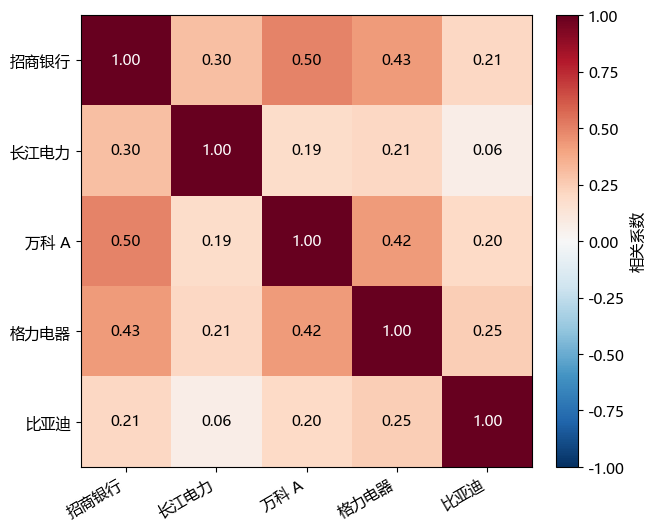

In [38]:
#| label: fig-mc-nb-portfolio-correlation
#| fig-cap: "五只股票的日收益相关系数；主对角线为 1。"
fig, axis = plt.subplots(figsize=(6.4, 5.2), layout='constrained')
correlations = portfolio_returns.corr().to_numpy()
picture = axis.imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
axis.set_xticks(range(5), stock_names, rotation=30, ha='right')
axis.set_yticks(range(5), stock_names)
for row in range(5):
    for column in range(5):
        axis.text(column, row, f'{correlations[row, column]:.2f}', ha='center', va='center',
                  color='white' if abs(correlations[row, column]) > .65 else 'black')
fig.colorbar(picture, ax=axis, label='相关系数')
plt.show()

### 两种生成方式保留什么 {.unnumbered}

正态模拟从历史估计的联合分布抽取收益，不是人为另定均值和协方差。整行重抽样则直接抽取某个历史交易日的五个收益，同时保留当天股票间的联系。两种方法各生成 100000 组单日收益，再按同一组权重计算组合收益。

这一步只比较单日分布，并不保留跨日联系。多日持有期将在区块部分单独处理。

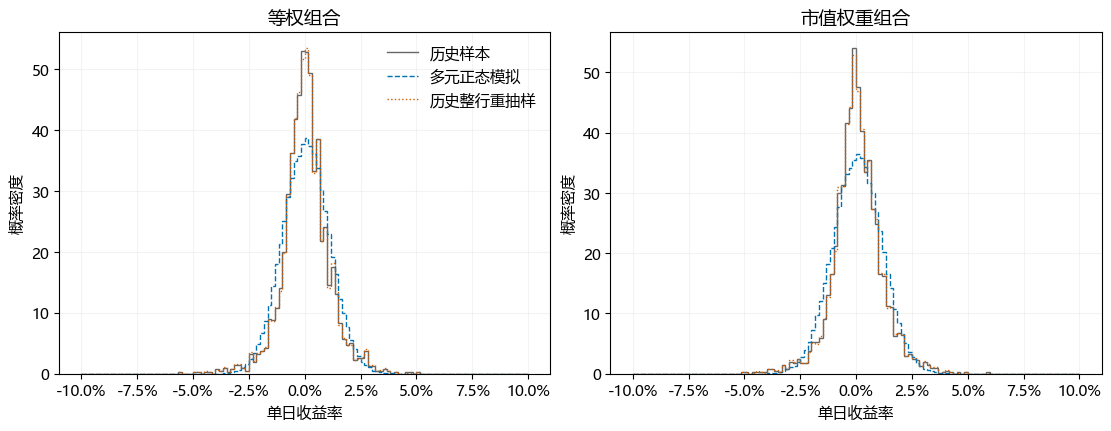

In [39]:
#| label: fig-mc-nb-portfolio-distributions
#| fig-cap: "同一组权重下的历史、正态模拟与整行重抽样单日组合收益分布。"
portfolio_B = 100000
portfolio_normal_rng = np.random.default_rng(SEED)
portfolio_boot_rng = np.random.default_rng(SEED + 1)
portfolio_normal = portfolio_normal_rng.multivariate_normal(portfolio_mu, portfolio_cov, size=portfolio_B)
portfolio_rows = portfolio_boot_rng.integers(0, len(portfolio_values), size=portfolio_B)
portfolio_boot = portfolio_values[portfolio_rows]
portfolio_arrays = {
    'Historical': portfolio_values @ portfolio_weights,
    'Parametric MC': portfolio_normal @ portfolio_weights,
    'Bootstrap': portfolio_boot @ portfolio_weights,
}
portfolio_method_names = {'Historical': '历史样本', 'Parametric MC': '多元正态模拟', 'Bootstrap': '历史整行重抽样'}
portfolio_display_names = {'Equal-weight': '等权组合', 'Value-weight': '市值权重组合'}
np.savez_compressed(OUTPUT / 'portfolio-single-day.npz', **portfolio_arrays)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, layout='constrained')
distribution_edges = np.linspace(-.10, .10, 121)
for column, axis in enumerate(axes):
    for method, color, style in [('Historical', '#666666', '-'), ('Parametric MC', '#0072B2', '--'), ('Bootstrap', '#D55E00', ':')]:
        values = portfolio_arrays[method][:, column]
        counts, edges = np.histogram(values, bins=distribution_edges)
        axis.stairs(counts / len(values) / np.diff(edges), edges,
                     label=portfolio_method_names[method], color=color, linestyle=style)
    axis.set(title=portfolio_names[column], xlabel='单日收益率', ylabel='概率密度')
    axis.xaxis.set_major_formatter(PercentFormatter(1))
    axis.grid(alpha=.15)
axes[0].legend(frameon=False)
plt.show()

### 用 VaR 与 ES 比较尾部损失 {.unnumbered}

将损失定义为收益率的相反数。95% 风险价值 (Value at Risk, VaR) 是损失分布的 95% 分位数，约有 5% 的结果损失超过该水平。95% 尾部平均损失 (Expected Shortfall, ES) 则是最差 5% 情景的平均损失。两者都是损失率，不是亏损概率。

历史样本的观测数乘以 5% 不一定为整数。下面将尾部边界上的观测按所需份额计入，使 ES 始终对应最差 5% 的经验概率质量。表图均为单日损失率，以百分比表示。

In [40]:
def portfolio_risk(values, alpha=.05):
    # 固定最差 alpha 的经验概率质量，不因相同取值而扩大尾部。
    losses = -np.asarray(values)
    ordered = np.sort(losses)[::-1]
    mass = len(losses) * alpha
    count = int(np.floor(mass))
    fraction = mass - count
    tail_sum = ordered[:count].sum()
    if fraction > 0:
        tail_sum += fraction * ordered[count]
    return float(np.quantile(losses, 1 - alpha)), float(tail_sum / mass)

portfolio_risk_rows = []
for method, values in portfolio_arrays.items():
    for column, portfolio in enumerate(['Equal-weight', 'Value-weight']):
        value95, es95 = portfolio_risk(values[:, column])
        value99, es99 = portfolio_risk(values[:, column], .01)
        portfolio_risk_rows.append({'portfolio': portfolio, 'method': method,
                                    'VaR_95': value95, 'ES_95': es95, 'VaR_99': value99, 'ES_99': es99})
portfolio_risks = pd.DataFrame(portfolio_risk_rows)
portfolio_risks.to_csv(OUTPUT / 'portfolio-risk-metrics.csv', index=False, encoding='utf-8-sig')
portfolio_main = portfolio_risks[['portfolio', 'method', 'VaR_95', 'ES_95']].copy()
portfolio_main[['VaR_95', 'ES_95']] *= 100
show_table(portfolio_main.replace(portfolio_method_names).replace(portfolio_display_names),
           {'portfolio': '组合', 'method': '生成方式', 'VaR_95': '95% VaR (%)', 'ES_95': '95% ES (%)'})

组合,生成方式,95% VaR (%),95% ES (%)
等权组合,历史样本,1.593,2.393
市值权重组合,历史样本,1.666,2.481
等权组合,多元正态模拟,1.681,2.120
市值权重组合,多元正态模拟,1.751,2.216
等权组合,历史整行重抽样,1.597,2.421
市值权重组合,历史整行重抽样,1.671,2.510


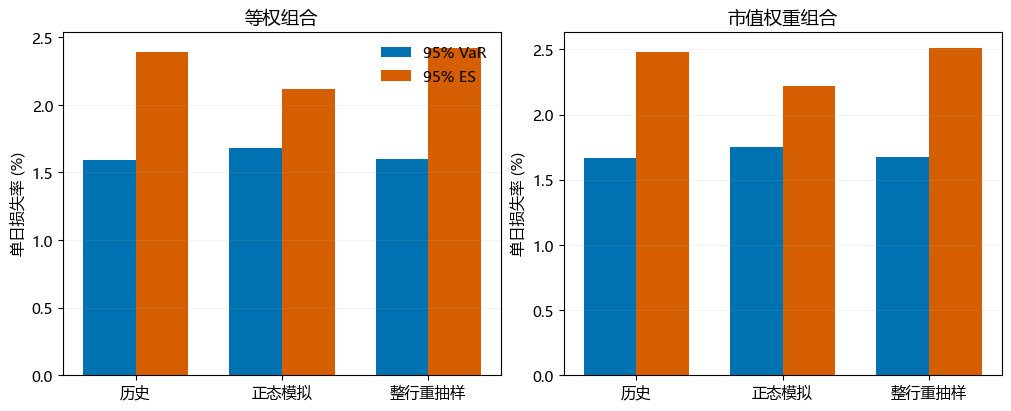

In [41]:
#| label: fig-mc-nb-portfolio-risk
#| fig-cap: "95% 单日 VaR 与 ES，损失率以百分比表示。"
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for column, portfolio in enumerate(['Equal-weight', 'Value-weight']):
    subset = portfolio_main[portfolio_main.portfolio == portfolio].set_index('method')
    positions = np.arange(3)
    axes[column].bar(positions-.18, subset.VaR_95, width=.36, label='95% VaR', color='#0072B2')
    axes[column].bar(positions+.18, subset.ES_95, width=.36, label='95% ES', color='#D55E00')
    axes[column].set_xticks(positions, ['历史', '正态模拟', '整行重抽样'])
    axes[column].set(title=portfolio_names[column], ylabel='单日损失率 (%)')
    axes[column].grid(axis='y', alpha=.15)
axes[0].legend(frameon=False)
plt.show()

以等权组合为例，历史 VaR 约为 1.593%，正态模拟约为 1.681%；历史 ES 约为 2.393%，正态模拟约为 2.120%。在本样本的 95% 水平下，正态模拟的损失分位点略高，却低估了尾部平均损失。整行重抽样的结果较接近历史值，但有限次重抽样仍有数值波动。

### 用区块抽样模拟多日组合收益 {.unnumbered #sec-mc-nb-block}

[返回正文：多日区块抽样](../../lectures/monte-carlo.qmd#sec-mc-portfolio)。

持有期限固定为 20 个交易日，期初按等权或市值权重配置，期间不调仓。区块长度取 5、10、20 日。候选窗口逐日移动且允许重叠，仅保留窗口内五只股票收益均有效的记录。

每种长度分别建立独立整行抽样对照，其日收益池由当前全部有效区块展开得到，保留窗口重叠引起的抽样权重。两种方式因而具有相同的单日经验抽样分布，区别主要在于是否成段保留连续记录。不同长度的有效窗口略有差异，应先在相同长度内比较。

先将每只股票逐日收益连乘得到期末价值，再按期初权重加总。不能把单日风险乘以根号 20，或把权重改为每天再平衡来替代这个实验。

In [42]:
def block_risk_metrics(values):
    ordered = np.sort(-values)[::-1]
    mass = len(values) * .05
    count = int(np.floor(mass))
    fraction = mass - count
    tail_sum = ordered[:count].sum()
    if fraction:
        tail_sum += fraction * ordered[count]
    return dict(mean=values.mean(), sd=values.std(ddof=1), q05=np.quantile(values, .05),
                VaR95=np.quantile(-values, .95), ES95=tail_sum / mass)

block_values = portfolio_returns.reindex(portfolio_prices.index).to_numpy()
block_horizon = 20
block_records, block_support, block_saved = [], [], {}
for block_length in [5, 10, 20]:
    starts = np.array([start for start in range(len(block_values)-block_length+1)
                       if np.isfinite(block_values[start:start+block_length]).all()])
    blocks = np.stack([block_values[start:start+block_length] for start in starts])
    assert block_horizon % block_length == 0 and np.isfinite(blocks).all()
    covered = np.unique((starts[:, None] + np.arange(block_length)).ravel())
    pool = blocks.reshape(-1, len(portfolio_returns.columns))
    block_support.append(dict(L=block_length, blocks=len(blocks), covered_days=len(covered), pool_size=len(pool)))
    for repetitions in [10000, 100000]:
        for seed in [20261017, 20261018, 20261019]:
            for method in ['iid', 'block']:
                # 按种子、区块长度和抽样方式分别初始化，分批生成以控制内存占用。
                block_rng = np.random.default_rng(np.random.SeedSequence([seed, block_length, method == 'block']))
                outcomes = []
                for offset in range(0, repetitions, 10000):
                    batch = min(10000, repetitions-offset)
                    if method == 'block':
                        selected = block_rng.integers(len(blocks), size=(batch, block_horizon//block_length))
                        paths = blocks[selected].reshape(batch, block_horizon, len(portfolio_returns.columns))
                    else:
                        selected = block_rng.integers(len(pool), size=(batch, block_horizon))
                        paths = pool[selected]
                    outcomes.append(np.prod(1+paths, axis=1) @ portfolio_weights - 1)
                outcomes = np.concatenate(outcomes)
                assert outcomes.shape == (repetitions, 2) and np.isfinite(outcomes).all()
                for column, name in enumerate(portfolio_names):
                    block_records.append(dict(L=block_length, B=repetitions, seed=seed, method=method,
                                              portfolio=name, **block_risk_metrics(outcomes[:, column])))
                if repetitions == 100000 and seed == 20261017:
                    block_saved[f'L{block_length}_{method}'] = outcomes

block_metrics = pd.DataFrame(block_records)
block_main = block_metrics.query('B == 100000 and seed == 20261017')
block_metrics.to_csv(OUTPUT / 'block-metrics-all.csv', index=False, encoding='utf-8-sig')
np.savez_compressed(OUTPUT / 'block-returns.npz', **block_saved)
pd.DataFrame(block_support).to_csv(OUTPUT / 'block-support.csv', index=False, encoding='utf-8-sig')
block_display = []
for name in portfolio_names:
    for length in [5, 10, 20]:
        subset = block_main[(block_main.portfolio == name) & (block_main.L == length)].set_index('method')
        block_display.append({'组合': name, '区块长度': length,
                              '独立 VaR (%)': subset.loc['iid', 'VaR95']*100,
                              '区块 VaR (%)': subset.loc['block', 'VaR95']*100,
                              '独立 ES (%)': subset.loc['iid', 'ES95']*100,
                              '区块 ES (%)': subset.loc['block', 'ES95']*100})
show_table(pd.DataFrame(block_display), digits=2)

组合,区块长度,独立 VaR (%),区块 VaR (%),独立 ES (%),区块 ES (%)
等权组合,5,6.78,6.67,8.66,8.73
等权组合,10,6.76,6.38,8.60,8.79
等权组合,20,6.81,6.08,8.71,7.98
市值权重组合,5,6.83,6.68,8.76,8.69
市值权重组合,10,6.81,6.56,8.71,8.80
市值权重组合,20,6.86,6.26,8.80,8.11


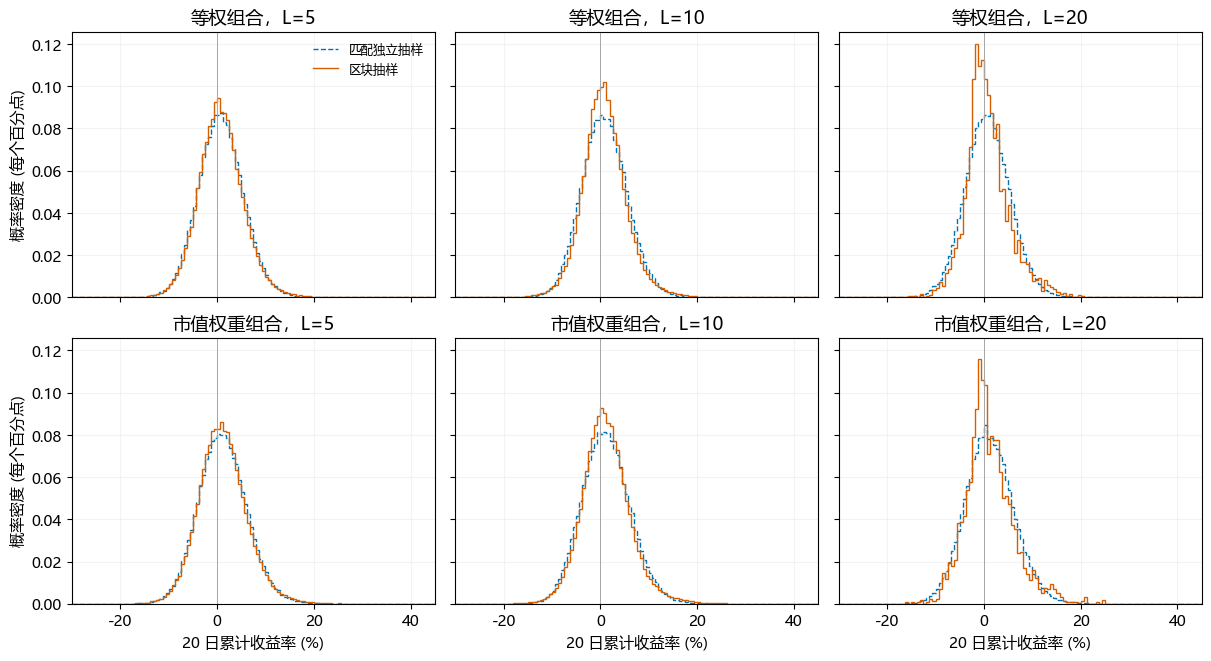

In [43]:
#| label: fig-mc-nb-block-distributions
#| fig-cap: "每组 100000 条 20 日买入持有路径；各面板坐标和分箱一致。"
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True, layout='constrained')
block_edges = np.linspace(-30, 45, 121)
for column, length in enumerate([5, 10, 20]):
    for portfolio, name in enumerate(portfolio_names):
        axis = axes[portfolio, column]
        for method, color, style, label in [('iid', '#0072B2', '--', '匹配独立抽样'), ('block', '#D55E00', '-', '区块抽样')]:
            values = block_saved[f'L{length}_{method}'][:, portfolio] * 100
            counts, edges = np.histogram(values, bins=block_edges)
            axis.stairs(counts/len(values)/np.diff(edges), edges, color=color, linestyle=style, label=label)
        axis.set(title=f'{name}，L={length}', xlim=(-30, 45))
        axis.axvline(0, color='.65', linewidth=.7)
        axis.grid(alpha=.15)
        if portfolio == 1:
            axis.set_xlabel('20 日累计收益率 (%)')
        if column == 0:
            axis.set_ylabel('概率密度 (每个百分点)')
axes[0, 0].legend(frameon=False, fontsize=9)
plt.show()

L=10 时，等权组合区块抽样的 VaR 约为 6.38%，ES 约为 8.79%。与匹配独立抽样比较，VaR 较低而 ES 较高，说明两项指标需要分别阅读。保留连续关系不必然提高风险估计，也不能因某个长度得到较低风险就认定它最合适。

::: {.callout-note collapse="true" title="补充分析：区块内部保留了哪些时间联系"}

收益率本身的自相关可能很弱，但较大波动仍可能连续出现。下面分别计算收益率及其平方的自相关。滞后 1 日表示比较相邻交易日，滞后 5 日表示比较间隔五个交易日的记录。收益平方的相关性可以帮助观察大幅波动是否倾向于成段出现。

In [44]:
block_acf = []
for lag in [1, 5, 10, 20]:
    for stock in portfolio_returns.columns:
        series = pd.Series(block_values[:, list(portfolio_returns.columns).index(stock)], index=portfolio_prices.index)
        block_acf.append({'stock': stock, 'lag': lag, 'return_acf': series.autocorr(lag),
                          'squared_return_acf': series.pow(2).autocorr(lag)})
block_acf = pd.DataFrame(block_acf)
block_acf.to_csv(OUTPUT / 'block-autocorrelations.csv', index=False, encoding='utf-8-sig')
acf_display = block_acf.query('lag in [1, 5]').copy()
acf_display['stock'] = acf_display['stock'].map(dict(zip(portfolio_returns.columns, stock_names)))
show_table(acf_display, {'stock': '股票', 'lag': '滞后交易日数', 'return_acf': '收益自相关',
                         'squared_return_acf': '收益平方自相关'})

股票,滞后交易日数,收益自相关,收益平方自相关
招商银行,1,-0.006,0.157
长江电力,1,-0.074,0.137
万科 A,1,0.027,0.204
格力电器,1,0.006,0.169
比亚迪,1,0.002,0.097
招商银行,5,-0.028,0.096
长江电力,5,0.007,0.041
万科 A,5,-0.011,0.119
格力电器,5,-0.070,0.122
比亚迪,5,-0.028,0.099


本样本中，收益率的一阶自相关较小，而五只股票收益平方的一阶自相关均为正，约在 0.097 至 0.204 之间。区块抽样保留整段记录，可以保留区块内部的这类联系；独立逐日抽样会将其打散。区块拼接处的联系仍会中断，不能据此声称完整保留了时间序列结构。

In [45]:
show_table(pd.DataFrame(block_support), {'L': '区块长度 (日)', 'blocks': '有效窗口数',
                                        'covered_days': '覆盖的有效日数', 'pool_size': '对照组日收益池大小'})

区块长度 (日),有效窗口数,覆盖的有效日数,对照组日收益池大小
5,2353,2397,11765
10,2300,2390,23000
20,2200,2390,44000


有效窗口允许重叠，因此日收益池大小可以超过历史交易日数。同一天进入几个窗口，就在对应的独立抽样池中出现几次。比较每个区块长度时，两种抽样方式使用相同的单日经验分布，差别主要来自是否整段保留日收益。

:::

::: {.callout-note collapse="true" title="补充分析：用完整 20 日窗口核对模拟结果"}

当区块长度与持有期限同为 20 日时，一条路径就是一个完整历史窗口。可以不作随机抽样，直接枚举全部有效窗口，计算其等概率经验分布，再与抽样结果对照。

In [46]:
exact_blocks = np.stack([block_values[start:start+20] for start in range(len(block_values)-19)
                         if np.isfinite(block_values[start:start+20]).all()])
exact_returns = np.prod(1+exact_blocks, axis=1) @ portfolio_weights - 1
exact_table = pd.DataFrame([{'portfolio': name, **block_risk_metrics(exact_returns[:, column])}
                            for column, name in enumerate(portfolio_names)])
exact_table.to_csv(OUTPUT / 'block-L20-exact.csv', index=False, encoding='utf-8-sig')
exact_comparison = []
for column, name in enumerate(portfolio_names):
    reference = exact_table.iloc[column]
    simulated = block_main[(block_main.L == 20) & (block_main.method == 'block')
                            & (block_main.portfolio == name)].iloc[0]
    exact_comparison.append({'组合': name, '完整窗口 VaR (%)': reference.VaR95 * 100,
                              '模拟 VaR (%)': simulated.VaR95 * 100,
                              '完整窗口 ES (%)': reference.ES95 * 100,
                              '模拟 ES (%)': simulated.ES95 * 100})
show_table(pd.DataFrame(exact_comparison))

组合,完整窗口 VaR (%),模拟 VaR (%),完整窗口 ES (%),模拟 ES (%)
等权组合,6.075,6.078,7.967,7.980
市值权重组合,6.261,6.260,8.073,8.109


模拟得到的 VaR 与 ES 接近完整窗口的计算值，差异来自有限次抽样。下图将各组的左尾放大，5% 水平线对应的收益率取负后，即为 95% VaR。这个对照检验抽样计算，不说明历史窗口已经覆盖未来全部风险。

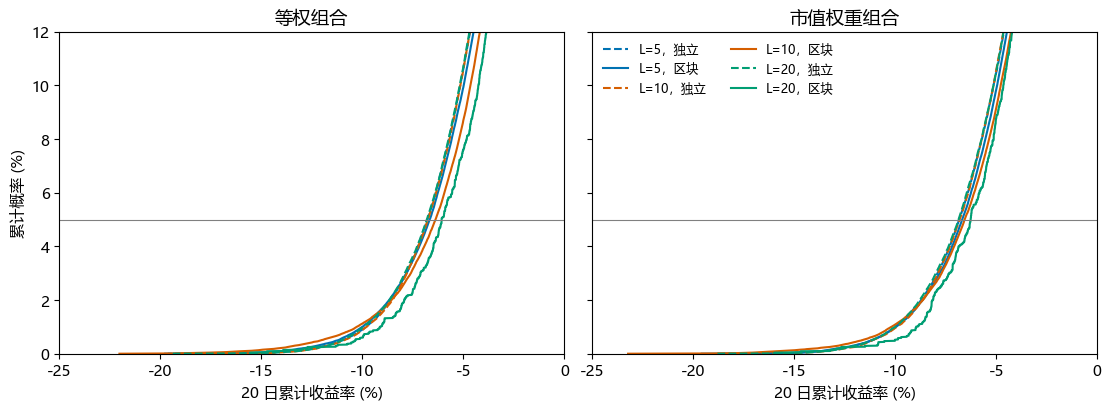

In [47]:
#| label: fig-mc-nb-block-tail
#| fig-cap: "左尾经验分布。5% 横线对应的收益率取负可读出 95% VaR。"
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout='constrained')
for portfolio, name in enumerate(portfolio_names):
    for length, color in [(5, '#0072B2'), (10, '#D55E00'), (20, '#009E73')]:
        for method, style in [('iid', '--'), ('block', '-')]:
            values = np.sort(block_saved[f'L{length}_{method}'][:, portfolio]) * 100
            indices = np.arange(0, int(len(values)*.12), 10)
            axes[portfolio].plot(values[indices], (indices+1)/len(values)*100, color=color, linestyle=style,
                                  label=f'L={length}，' + ('区块' if method == 'block' else '独立'))
    axes[portfolio].axhline(5, color='.5', linewidth=.8)
    axes[portfolio].set(title=name, xlabel='20 日累计收益率 (%)', xlim=(-25, 0), ylim=(0, 12))
axes[0].set_ylabel('累计概率 (%)')
axes[1].legend(frameon=False, fontsize=9, ncol=2)
plt.show()

:::

::: {.callout-note collapse="true" title="补充分析：正态模型的计算结果能否相互核对"}

若五只股票的收益服从本例设定的联合正态分布，固定权重下的组合收益也服从正态分布，均值为 $\mathbf{w}^{\prime}\hat{\boldsymbol{\mu}}$，方差为 $\mathbf{w}^{\prime}\hat{\Sigma}\mathbf{w}$。因此可以直接计算 VaR 与 ES，与随机模拟结果对照。下面还比较忽略或保留股票相关性时的组合标准差。

In [48]:
analytic_rows = []
for column, name in enumerate(portfolio_names):
    weights = portfolio_weights[:, column]
    mean = portfolio_mu @ weights
    deviation = np.sqrt(weights @ portfolio_cov @ weights)
    analytic_rows.append({'组合': name, '解析正态95%VaR': -mean+norm.ppf(.95)*deviation,
                          '解析正态95%ES': -mean+norm.pdf(norm.ppf(.95))/.05*deviation,
                          '忽略相关性标准差': np.sqrt(weights @ np.diag(np.diag(portfolio_cov)) @ weights),
                          '保留相关性标准差': deviation})
analytic_display = pd.DataFrame(analytic_rows)
numeric_columns = analytic_display.select_dtypes(include='number').columns
analytic_display[numeric_columns] *= 100
show_table(analytic_display, {'解析正态95%VaR': '解析 95% VaR (%)', '解析正态95%ES': '解析 95% ES (%)',
                              '忽略相关性标准差': '忽略相关性的标准差 (%)',
                              '保留相关性标准差': '保留相关性的标准差 (%)'})

组合,解析 95% VaR (%),解析 95% ES (%),忽略相关性的标准差 (%),保留相关性的标准差 (%)
等权组合,1.678,2.113,0.748,1.043
市值权重组合,1.755,2.215,0.915,1.101


解析风险值与前面的正态模拟结果接近。等权组合若忽略相关性，单日标准差约为 0.748%；保留相关性后约为 1.043%。本样本中的正相关提高了组合波动，不能通过独立生成个股收益来省略这部分联系。

:::

::: {.callout-note collapse="true" title="补充分析：增加重复次数后，风险指标有多稳定"}

保持数据、权重和生成方式不变，使用三个种子及不同重复次数计算风险指标。下面的区间是三个种子所得结果的最小值至最大值，用来观察数值波动，不是未来损失或风险参数的置信区间。区块表以 10 日区块为例，完整明细导出到开头指定的结果目录。

In [49]:
block_stability = (block_metrics.query('L == 10')
                   .groupby(['B', 'method', 'portfolio'])[['VaR95', 'ES95']].agg(['min', 'max']))
block_stability.columns = ['VaR 最小值 (%)', 'VaR 最大值 (%)', 'ES 最小值 (%)', 'ES 最大值 (%)']
block_stability *= 100
show_table(block_stability.reset_index().replace({'iid': '独立抽样', 'block': '区块抽样'}),
           {'B': '重复次数 B', 'method': '抽样方式', 'portfolio': '组合'})

重复次数 B,抽样方式,组合,VaR 最小值 (%),VaR 最大值 (%),ES 最小值 (%),ES 最大值 (%)
10000,区块抽样,市值权重组合,6.542,6.666,8.855,8.980
10000,区块抽样,等权组合,6.344,6.542,8.810,8.909
10000,独立抽样,市值权重组合,6.784,6.952,8.655,8.914
10000,独立抽样,等权组合,6.745,6.929,8.526,8.717
100000,区块抽样,市值权重组合,6.534,6.588,8.760,8.860
100000,区块抽样,等权组合,6.379,6.422,8.758,8.859
100000,独立抽样,市值权重组合,6.812,6.890,8.710,8.835
100000,独立抽样,等权组合,6.764,6.846,8.603,8.717


In [50]:
portfolio_stability = []
for stability_seed in [SEED+10, SEED+20, SEED+30]:
    normal_rng = np.random.default_rng(stability_seed)
    bootstrap_rng = np.random.default_rng(stability_seed+1)
    normal_paths = normal_rng.multivariate_normal(portfolio_mu, portfolio_cov, size=500000) @ portfolio_weights
    bootstrap_paths = portfolio_values[bootstrap_rng.integers(0, len(portfolio_values), size=500000)] @ portfolio_weights
    for size in [10000, 50000, 100000, 500000]:
        for method, values in [('Parametric MC', normal_paths), ('Bootstrap', bootstrap_paths)]:
            for column, name in enumerate(['Equal-weight', 'Value-weight']):
                value95, es95 = portfolio_risk(values[:size, column])
                portfolio_stability.append({'seed': stability_seed, 'B': size, 'portfolio': name,
                                            'method': method, 'VaR_95': value95, 'ES_95': es95})
portfolio_stability = pd.DataFrame(portfolio_stability)
portfolio_stability.to_csv(OUTPUT / 'portfolio-stability.csv', index=False, encoding='utf-8-sig')
daily_stability = (portfolio_stability.query('B in [10000, 500000]')
                   .groupby(['B', 'portfolio', 'method'])[['VaR_95', 'ES_95']].agg(['min', 'max']))
daily_stability.columns = ['VaR 最小值 (%)', 'VaR 最大值 (%)', 'ES 最小值 (%)', 'ES 最大值 (%)']
daily_stability *= 100
show_table(daily_stability.reset_index().replace(portfolio_method_names).replace(portfolio_display_names),
           {'B': '重复次数 B', 'portfolio': '组合', 'method': '单日生成方式'})

重复次数 B,组合,单日生成方式,VaR 最小值 (%),VaR 最大值 (%),ES 最小值 (%),ES 最大值 (%)
10000,等权组合,历史整行重抽样,1.546,1.593,2.265,2.396
10000,等权组合,多元正态模拟,1.647,1.680,2.069,2.108
10000,市值权重组合,历史整行重抽样,1.562,1.658,2.351,2.471
10000,市值权重组合,多元正态模拟,1.725,1.777,2.162,2.221
500000,等权组合,历史整行重抽样,1.594,1.597,2.391,2.392
500000,等权组合,多元正态模拟,1.672,1.677,2.105,2.111
500000,市值权重组合,历史整行重抽样,1.671,1.676,2.482,2.487
500000,市值权重组合,多元正态模拟,1.753,1.757,2.210,2.213


In [51]:
#| include: false
case_results['portfolio'] = {'daily_risk_rows': len(portfolio_risks), 'block_metric_rows': len(block_metrics),
                              'sample_rows': len(portfolio_returns), 'block_support': block_support}

在这些重复实验中，增加抽样次数通常缩小了种子之间的风险指标差异。但这只说明当前模型下的数值近似更稳定，不会扩大历史样本所覆盖的市场状态，也不能据此选择给出最低风险的区块长度。

:::

## 案例四：从随机变量到随机过程 {.unnumbered #sec-mc-nb-process}

[返回正文：案例四](../../lectures/monte-carlo.qmd#sec-mc-process)。

本例关注期末上涨与途中跌破阈值两类事件。二者都从价格路径计算，但回答不同问题。下面依次用随机游走说明冲击累积、用布朗运动说明时间尺度，再用几何布朗运动生成始终为正的价格路径。

### 随机游走 {.unnumbered}

从 $X_{0}=0$ 出发，每一步按 $X_{k+1}=X_{k}+\varepsilon_{k+1}$ 更新，其中各步冲击 $\varepsilon_{k}$ 独立且服从标准正态分布。独立抽取的是新增冲击，不是各时点的取值，过去冲击的影响会累积在路径中。横轴为离散步数，每步冲击标准差为 1，此时还没有将时间和波动换算为资产收益的年化尺度。

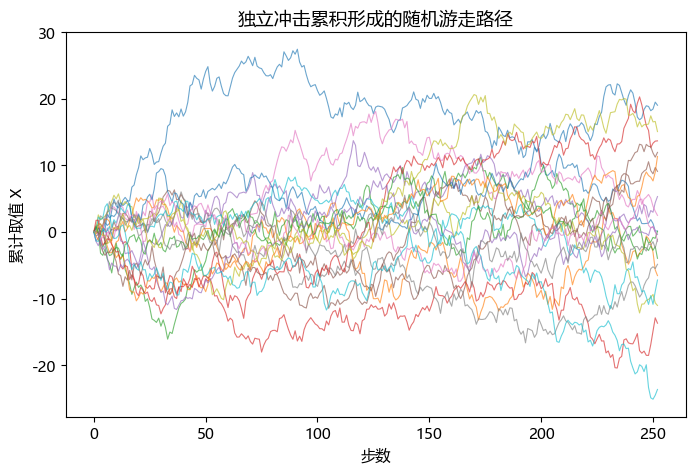

In [52]:
#| label: fig-mc-nb-random-walk
#| fig-cap: "独立冲击逐步累积形成的随机游走路径。"
rng = np.random.default_rng(SEED)
T_steps = 252
n_paths = 20
eps = rng.normal(0, 1, size=(n_paths, T_steps))
paths = np.c_[np.zeros(n_paths), np.cumsum(eps, axis=1)]
fig, ax = plt.subplots(figsize=(8,5))
for row in paths:
    ax.plot(row, linewidth=0.8, alpha=0.65)
ax.set_xlabel("步数"); ax.set_ylabel("累计取值 X"); ax.set_title("独立冲击累积形成的随机游走路径")
plt.show()

### 布朗运动 {.unnumbered}

将一年划分为 252 步，每步长度为 $\Delta t=1/252$ 年。布朗运动从 $W_{0}=0$ 开始，在这些时点上按下式生成：

$$
W_{t_{k+1}}=W_{t_{k}}+\sqrt{\Delta t}\,Z_{k+1},
\qquad Z_{k+1}\overset{\mathrm{iid}}{\sim}N(0,1).
$$ {#eq-mc-nb-brownian}

新增冲击的方差为 $\Delta t$，各段方差加总后，一年的累计方差为 1。这样加密时间网格时不会人为增大整年的波动。下图展示 20 条路径，随后独立抽取 100000 个终点，与 $W_{T}\sim N(0,T)$ 的理论均值和标准差比较。

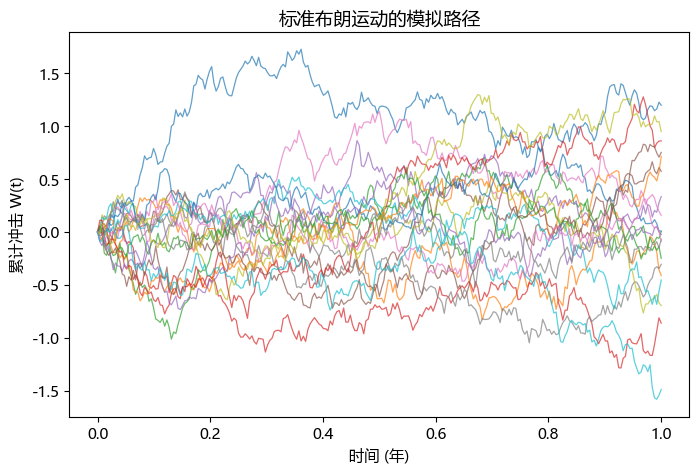

In [53]:
#| label: fig-mc-nb-brownian
#| fig-cap: "一年时间网格上的布朗运动路径。"
T = 1.0
N = 252
dt = T / N
rng = np.random.default_rng(SEED)
dW = rng.normal(0, np.sqrt(dt), size=(20, N))
W = np.c_[np.zeros(20), np.cumsum(dW, axis=1)]
t = np.linspace(0, T, N + 1)
fig, ax = plt.subplots(figsize=(8,5))
for row in W:
    ax.plot(t, row, linewidth=0.9, alpha=0.7)
ax.set_xlabel("时间 (年)"); ax.set_ylabel("累计冲击 W(t)"); ax.set_title("标准布朗运动的模拟路径")
plt.show()

In [54]:
rng = np.random.default_rng(SEED)
WT = rng.normal(0, np.sqrt(T), size=100000)
brownian_summary = pd.Series({
    "mean_WT": WT.mean(),
    "sd_WT": WT.std(ddof=1),
    "theoretical_mean": 0.0,
    "theoretical_sd": np.sqrt(T),
})
show_table(pd.DataFrame({'指标': ['均值', '标准差'],
                         '模拟结果': [brownian_summary['mean_WT'], brownian_summary['sd_WT']],
                         '理论值': [0.0, np.sqrt(T)]}))

指标,模拟结果,理论值
均值,-0.002,0.000
标准差,1.000,1.000


本次抽样的终点均值约为 -0.002，标准差约为 1.000，与一年期标准布朗运动的理论值 0 和 1 接近。该检查只针对终点分布，不能单独验证路径上全部时点的依赖关系。

### 几何布朗运动 {.unnumbered}

几何布朗运动 (Geometric Brownian Motion, GBM) 将累积冲击引入对数价格，价格取值为

$$
S_{t}=S_{0}\exp\!\left[\left(\mu-\frac{1}{2}\sigma^{2}\right)t+\sigma W_{t}\right].
$$ {#eq-mc-nb-gbm}

其中 $S_{0}$ 为初始价格，$\mu$ 控制预期价格的增长，$\sigma$ 为年化波动率，$t$ 以年计。指数变换保证价格为正，减去 $\sigma^{2}/2$ 则使预期价格按 $\mu$ 指定的速度增长。代码先累积各步布朗增量，再直接计算网格时点的价格。

下面固定 $S_{0}=100$、$\mu=0.08$ 和一年期限，分别取 $\sigma=0.10$ 与 $0.35$，各画 30 条路径。两组使用不同种子，比较的是整体分散程度，不是共用冲击下的逐条路径。

In [55]:
def gbm_paths(S0=100, mu=0.08, sigma=0.2, T=1.0, N=252, n_paths=50, seed=SEED):
    rng = np.random.default_rng(seed)
    dt = T / N
    dW = rng.normal(0, np.sqrt(dt), size=(n_paths, N))
    W = np.c_[np.zeros(n_paths), np.cumsum(dW, axis=1)]
    t = np.linspace(0, T, N + 1)
    S = S0 * np.exp((mu - 0.5*sigma**2)*t[None,:] + sigma*W)
    return t, S

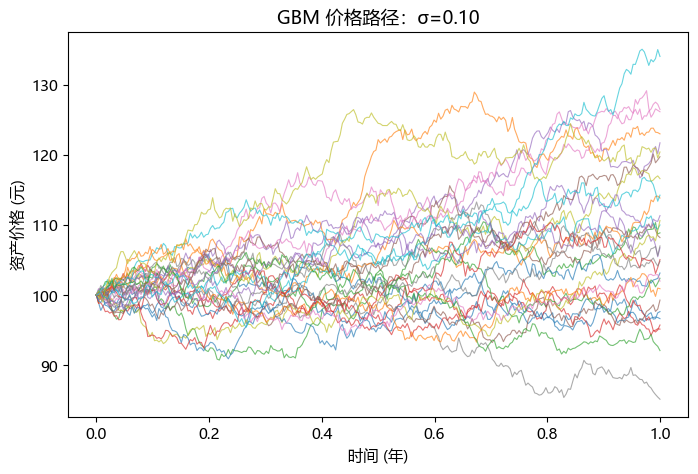

In [56]:
#| label: fig-mc-nb-gbm-low
#| fig-cap: "年化波动率为 0.10 的 GBM 价格路径。"
sigma = 0.1
t, S = gbm_paths(sigma=sigma, n_paths=30, seed=SEED + int(sigma*1000))
fig, ax = plt.subplots(figsize=(8, 5))
for row in S:
    ax.plot(t, row, linewidth=0.8, alpha=0.65)
ax.set(xlabel='时间 (年)', ylabel='资产价格 (元)', title=f'GBM 价格路径：σ={sigma:.2f}')
plt.show()

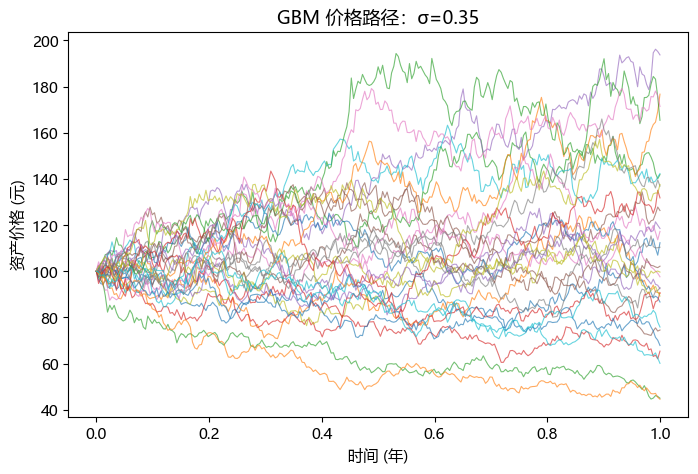

In [57]:
#| label: fig-mc-nb-gbm-high
#| fig-cap: "年化波动率为 0.35 的 GBM 价格路径。"
sigma = 0.35
t, S = gbm_paths(sigma=sigma, n_paths=30, seed=SEED + int(sigma*1000))
fig, ax = plt.subplots(figsize=(8, 5))
for row in S:
    ax.plot(t, row, linewidth=0.8, alpha=0.65)
ax.set(xlabel='时间 (年)', ylabel='资产价格 (元)', title=f'GBM 价格路径：σ={sigma:.2f}')
plt.show()

### 终值风险和路径风险 {.unnumbered}

主风险实验设初始价格为 100 元、漂移率为 0.08、波动率为 0.30、期限为 1 年，生成 5000 条各含 252 步的路径。将 75 元设为风险监测阈值，分别统计期末价格高于 100 元、网格价格曾低于 75 元，以及两者同时发生的路径。下表列出各事件的路径数，概率分母均为 5000。

这不是止损交易模拟，也不是最大回撤。统计仅监测离散网格时点，不保证捕捉时点之间的连续越界。

In [58]:
S0=100; mu=0.08; sigma=0.30; T=1; N=252; n_paths=5000; barrier=75
t, S = gbm_paths(S0=S0, mu=mu, sigma=sigma, T=T, N=N, n_paths=n_paths, seed=SEED)
terminal = S[:, -1]
hit_barrier = (S.min(axis=1) < barrier)

In [59]:
path_events = pd.DataFrame({
    '事件': ['期末上涨', '网格中曾跌破75', '期末上涨且网格中曾跌破75'],
    '计数': [int((terminal > S0).sum()), int(hit_barrier.sum()), int(((terminal > S0) & hit_barrier).sum())],
})
path_events['分母'] = n_paths
path_events['概率 (%)'] = path_events['计数'] / n_paths * 100
show_table(path_events.assign(事件=path_events['事件'].str.replace('跌破75', '跌破 75 元')),
           {'计数': '路径条数', '分母': '全部路径数'}, digits=2)

事件,路径条数,全部路径数,概率 (%)
期末上涨,2749,5000,54.98
网格中曾跌破 75 元,1402,5000,28.04
期末上涨且网格中曾跌破 75 元,133,5000,2.66


In [60]:
#| include: false
path_events.to_csv(OUTPUT / 'path-events.csv', index=False, encoding='utf-8-sig')
case_results['path_risk'] = {'B': int(n_paths), 'counts': path_events['计数'].tolist(),
                             'parameters': {'S0': float(S0), 'mu': float(mu), 'sigma': float(sigma),
                                             'T': float(T), 'N': int(N), 'barrier': float(barrier)}}

期末上涨的路径仍可能在途中跌破 75 元。按本页设定，两类单独事件和联合事件分别约为 54.98%、28.04% 和 2.66%。第三项不是以期末上涨路径为分母的条件概率。

::: {.callout-note collapse="true" title="扩展阅读：Monte Carlo 期权定价"}

欧式看涨期权到期支付为 $\max(S_{T}-K,0)$，只与终值有关，因此本例直接模拟终值，不必生成完整路径。风险中性分布的漂移使用无风险利率，不能将其中的上涨概率解释为现实发生概率。

其中，$S_{T}$ 为到期价格，$K$ 为执行价格。本段采用无分红、无交易成本、可连续交易且利率和波动率恒定的 Black–Scholes 模型，另设初始价与执行价均为 100 元、连续复利无风险年利率 0.05、年化波动率 0.20、期限 1 年，独立模拟 100000 个终值。

先计算各情景折现支付的平均值，得到 MC 价格，再用折现支付的样本标准差除以模拟次数的平方根，得到 MC 标准误。Black–Scholes 闭式价格是同一模型下可直接计算的理论基准，不是另一个市场价格观测。比较二者，可以检查模拟计算的精度。

In [61]:
def normal_cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def bs_call_price(S0, K, r, sigma, T):
    d1 = (log(S0/K)+(r+0.5*sigma**2)*T)/(sigma*sqrt(T))
    d2 = d1 - sigma*sqrt(T)
    return S0*normal_cdf(d1) - K*exp(-r*T)*normal_cdf(d2)

def mc_call_price(S0, K, r, sigma, T, B, seed=SEED):
    rng = np.random.default_rng(seed)
    Z = rng.normal(size=B)
    ST = S0*np.exp((r-0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
    payoff = np.maximum(ST-K, 0)
    return np.exp(-r*T)*payoff.mean()

S0=100; K=100; r=0.05; sigma=0.20; T=1.0
bs_price = bs_call_price(S0,K,r,sigma,T)
mc_price = mc_call_price(S0,K,r,sigma,T,B=100000)

In [62]:
pricing_B = 100000
pricing_rng = np.random.default_rng(SEED)
pricing_shocks = pricing_rng.normal(size=pricing_B)
pricing_terminal = S0 * np.exp((r-.5*sigma**2)*T + sigma*np.sqrt(T)*pricing_shocks)
discounted_payoff = np.exp(-r*T) * np.maximum(pricing_terminal-K, 0)
pricing_mcse = discounted_payoff.std(ddof=1) / np.sqrt(pricing_B)
assert np.isclose(discounted_payoff.mean(), mc_price)
show_table(pd.DataFrame({'指标': ['MC 价格', 'Black–Scholes 闭式价格', 'MC 标准误', 'MC 价格减去闭式价格'],
                         '数值 (元)': [mc_price, bs_price, pricing_mcse, mc_price-bs_price]}), digits=4)

指标,数值 (元)
MC 价格,10.4165
Black–Scholes 闭式价格,10.4506
MC 标准误,0.0463
MC 价格减去闭式价格,-0.0341


In [63]:
#| include: false
case_results['option'] = {'MC': float(mc_price), 'closed_form': float(bs_price), 'MCSE': float(pricing_mcse)}

In [64]:
B_grid = [100,500,1000,5000,10000,50000,100000]
rows=[]
for B in B_grid:
    p = mc_call_price(S0,K,r,sigma,T,B=B,seed=SEED)
    rows.append({"B":B,"MC_price":p,"error_vs_BS":p-bs_price})
conv = pd.DataFrame(rows)
show_table(conv, {'B': '模拟次数 B', 'MC_price': 'MC 价格 (元)', 'error_vs_BS': 'MC 价格减去闭式价格 (元)'}, digits=4)

模拟次数 B,MC 价格 (元),MC 价格减去闭式价格 (元)
100,13.6391,3.1885
500,10.8551,0.4045
1000,10.5654,0.1148
5000,10.5100,0.0594
10000,10.5162,0.0656
50000,10.4496,-0.0010
100000,10.4165,-0.0341


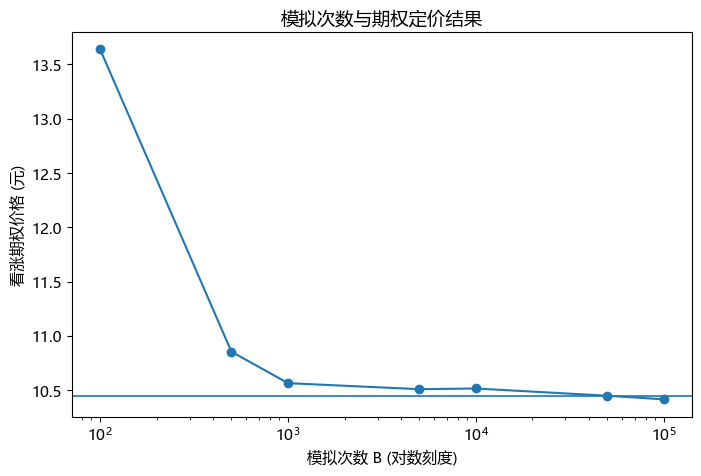

In [65]:
#| label: fig-mc-nb-option-convergence
#| fig-cap: "不同重复次数下 MC 价格与闭式价格比较，误差不要求单调下降。"
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(conv["B"], conv["MC_price"], marker="o")
ax.axhline(bs_price, linewidth=1.2)
ax.set_xscale("log")
ax.set_xlabel("模拟次数 B (对数刻度)")
ax.set_ylabel("看涨期权价格 (元)")
ax.set_title("模拟次数与期权定价结果")
plt.show()

本参数下 MC 价格约为 10.4165，闭式价格约为 10.4506，MC 标准误约为 0.0463。这个对照用于核验计算，并不证明真实资产价格符合 GBM。

:::

## 从案例回到模拟设计 {.unnumbered #sec-mc-nb-output}

四个案例使用 MC 回答不同问题：比较估计量、评价项目价值、估计组合损失，以及识别价格路径中的风险事件。更换问题时，需要相应调整生成机制和评价指标，计算稳定也不意味着模型一定适用。

[返回正文的五项检查](../../lectures/monte-carlo.qmd#sec-mc-reliable)，结合案例检查自己的模拟设计。

In [66]:
#| include: false
(OUTPUT / 'run-summary.json').write_text(json.dumps(case_results, ensure_ascii=False, indent=2), encoding='utf-8')

1553